# EEG waves, amplitude and frequency — and what MNE filters do to them

Author: Christos Dalamarinis

This notebook has two halves:

* **Part A — Understanding EEG waves (sections 1–6).** What an EEG signal is, why it is measured in
  **microvolts (µV)**, what *frequency*, *amplitude* and *phase* mean, the classic frequency bands, and the
  relationship between amplitude and frequency (the **1/f rule**). We then build a complete, realistic
  *simulated* EEG recording, artifacts included.
* **Part B — What MNE filters do (sections 7–9).** We apply `mne` filters with many different settings to the
  simulated recording and look at what they do to the waves — in the time domain, in the frequency domain, and
  in the filter's own response.

**Why simulate?** Because we know the ground truth. With real EEG you never know what the "true" brain signal
was, so you cannot say how much a filter distorted it. Here we know exactly what we put in, so we can measure
every filter's side-effects.

## Contents
1. What does EEG measure? (units)
2. Anatomy of a wave: frequency, period, amplitude, phase
3. The classic frequency bands
4. Amplitude versus frequency: the 1/f rule
5. Modulated oscillations (in the style of `sine_models.ipynb`)
6. A complete simulated EEG recording
7. MNE filtering: the basics
8. Filter settings: what changes, and why it matters
9. Interactive filter explorer
10. Take-home messages and further reading

## Conventions used throughout
* **All simulated signals are kept in µV** (what people quote in papers). MNE, however, stores EEG in **volts**,
  so `make_raw()` multiplies by 1e-6 and plots multiply by 1e6 on the way out.
* Plot colours follow `sine_models.ipynb`: carrier = blue, modulator = red, envelope = green,
  modulated signal = purple.
* Everything is seeded, so every run gives the same recording. Change `SEED` to get a different one.
* Needs: `mne`, `numpy`, `scipy`, `matplotlib`, `ipywidgets` (interactive cells only).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sps
import mne
import ipywidgets as widgets
from ipywidgets import interact, fixed

mne.set_log_level("WARNING")  # keep MNE quiet unless we explicitly ask for details

# ----- global parameters (easily adjustable) -----
FS = 1000        # Hz - sampling rate of the simulated EEG; must be > 2 x the highest frequency we care about
LINE_FREQ = 50   # Hz - mains frequency (50 Hz in Europe/Asia/Africa, 60 Hz in the Americas)
SEED = 2024      # random seed
rng = np.random.default_rng(SEED)

# Colours for carrier / modulator / envelope / modulated signal (same as sine_models.ipynb)
C_CARRIER, C_MOD, C_ENV, C_AM = "tab:blue", "tab:red", "tab:green", "purple"

plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
    "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 11, "axes.labelweight": "bold",
    "legend.fontsize": 9,
})
print(f"MNE {mne.__version__} | NumPy {np.__version__} | SciPy {__import__('scipy').__version__}")
print(f"Sampling rate {FS} Hz -> Nyquist frequency {FS / 2:.0f} Hz")

MNE 1.12.1 | NumPy 2.4.4 | SciPy 1.17.1
Sampling rate 1000 Hz -> Nyquist frequency 500 Hz


### Helper functions
Small building blocks used throughout. Run this cell once; you can skip reading it.

In [2]:
def time_vec(duration, fs=FS):
    """Time axis in seconds for `duration` seconds sampled at `fs` Hz."""
    return np.arange(int(round(duration * fs))) / fs


def sine(t, freq, amp=1.0, phase=0.0):
    """amp * sin(2*pi*freq*t + phase). For EEG, `amp` is in µV and `phase` in radians."""
    return amp * np.sin(2 * np.pi * freq * t + phase)


def rms(x, axis=-1):
    """Root-mean-square amplitude."""
    return np.sqrt(np.mean(np.square(x), axis=axis))


def shaped_noise(n, fs, gain_fn, rms_uV, rng):
    """Gaussian noise whose *amplitude spectrum* is multiplied by gain_fn(freq); rescaled to a given RMS (µV)."""
    spec = np.fft.rfft(rng.standard_normal(n))
    freqs = np.fft.rfftfreq(n, 1 / fs)
    x = np.fft.irfft(spec * gain_fn(freqs), n)
    return (x - x.mean()) * rms_uV / x.std()


def pink_noise(n, fs, exponent, rms_uV, rng, fmin=1.0, fmax=None):
    """'1/f^exponent' noise: power ∝ 1/f^exponent between fmin and fmax (0 = white, 1 = pink, 2 = brown)."""
    fmax = fmax or fs / 2

    def gain(f):
        g = np.zeros_like(f)
        ok = (f >= fmin) & (f <= fmax)
        g[ok] = f[ok] ** (-exponent / 2)  # amplitude ∝ f^(-exponent/2)  <=>  power ∝ f^(-exponent)
        return g

    return shaped_noise(n, fs, gain, rms_uV, rng)


def narrowband_noise(n, fs, f0, bw, rms_uV, rng):
    """Random oscillation centred on f0 (Hz) with spread `bw` (Hz) - waxes and wanes like real alpha."""
    return shaped_noise(n, fs, lambda f: np.exp(-0.5 * ((f - f0) / bw) ** 2), rms_uV, rng)


def welch_uV(x, fs=FS, seconds=4):
    """Power spectral density in µV²/Hz of a signal given in µV (Welch's method)."""
    nperseg = int(min(len(x), seconds * fs))
    return sps.welch(x, fs=fs, nperseg=nperseg, noverlap=nperseg // 2, window="hann")


def make_raw(data_uV, ch_names, fs=FS):
    """Wrap an array (channels x samples, in µV) in an MNE Raw object. MNE wants VOLTS, hence the 1e-6."""
    info = mne.create_info(list(ch_names), fs, ch_types="eeg")
    return mne.io.RawArray(np.atleast_2d(data_uV) * 1e-6, info, verbose=False)


def raw_uV(raw):
    """Data of an MNE Raw object back in µV (channels x samples)."""
    return raw.get_data() * 1e6


def stack_plot(data_uV, t, ch_names, ax=None, spacing=150, scale_bar=100, color="k", lw=0.7, title=None):
    """Classic EEG 'stacked channels' view with a µV scale bar."""
    data_uV = np.atleast_2d(data_uV)
    if ax is None:
        _, ax = plt.subplots(figsize=(12, 0.75 * len(data_uV) + 1.2))
    offsets = -np.arange(len(data_uV)) * spacing
    for trace, off in zip(data_uV, offsets):
        ax.plot(t, trace + off, color=color, lw=lw)
    ax.set_yticks(offsets)
    ax.set_yticklabels(ch_names)
    span = t[-1] - t[0]
    x0, y_top = t[0] + 0.008 * span, offsets[0] + 0.85 * spacing
    ax.plot([x0, x0], [y_top - scale_bar, y_top], color="k", lw=3)
    ax.text(x0 + 0.008 * span, y_top - scale_bar / 2, f"{scale_bar} µV", ha="left", va="center", fontsize=9,
            bbox=dict(fc="white", ec="none", alpha=0.8))
    ax.set_xlim(t[0], t[-1])
    ax.set_ylim(offsets[-1] - spacing * 0.7, offsets[0] + spacing * 0.9)
    ax.set_xlabel("Time (s)")
    ax.grid(axis="y", alpha=0)
    if title:
        ax.set_title(title)
    return ax

print("helpers ready")

helpers ready


---
# Part A — Understanding EEG waves

## 1. What does EEG measure?

**Electroencephalography (EEG)** records tiny voltage fluctuations on the scalp. They come mostly from the
summed *postsynaptic potentials* of large groups of similarly oriented cortical (pyramidal) neurons that are
active **at the same time**. A single neuron is invisible from the scalp; it takes thousands to millions of
roughly synchronous neurons. The skull, cerebrospinal fluid and scalp then smear and weaken the signal
(*volume conduction*), which is one reason scalp EEG is far smaller than recordings made directly on the cortex.

EEG is always a **voltage difference** between an electrode and a reference, so its physical unit is the volt.
The voltages are so small that we quote **microvolts**:

$$1\ \mu V = 10^{-6}\ V = 0.000001\ V$$

Rough orders of magnitude at the scalp (they vary with person, electrode position, reference and amplifier —
treat them as a feel for the scale, not as exact values):

| Signal | Typical size |
|---|---|
| Ongoing ("background") EEG | ~10–100 µV |
| Event-related potentials (ERPs) | ~1–10 µV — *much smaller than the background EEG* |
| Eye blinks (frontal electrodes) | ~100 µV up to a few hundred µV |
| Muscle activity (EMG), e.g. clenched jaw | can exceed 100 µV; fast and broadband |
| Slow electrode drift (sweat, movement) | tens to hundreds of µV; very slow |
| Mains (line) noise | from ~1 µV to hundreds of µV, depending on set-up |
| *For comparison:* ECG measured on the chest | ~1000 µV (1 mV) |

Two consequences shape everything that follows:
1. The brain signal we care about is **small compared with the artifacts**, so we usually need filtering.
2. ERPs are **smaller than the ongoing EEG**, so we need many repetitions and averaging.

## 2. Anatomy of a wave

A pure sine wave is described by four numbers:

| Quantity | Symbol | Meaning | Unit |
|---|---|---|---|
| Frequency | *f* | cycles per second | Hz |
| Period | *T = 1/f* | duration of one cycle | s (or ms) |
| Amplitude | *A* | size of the wave | µV |
| Phase | *φ* | where in its cycle the wave is at *t = 0* | radians or degrees |

"Amplitude" has **three** common meanings, so always check which one is meant:

| Definition | Value for a sine wave with peak amplitude *A* |
|---|---|
| Peak | *A* |
| Peak-to-peak | *2A* — what clinical EEG reports usually quote |
| RMS (root-mean-square) | *A/√2 ≈ 0.707 A* — what spectral analysis effectively measures |

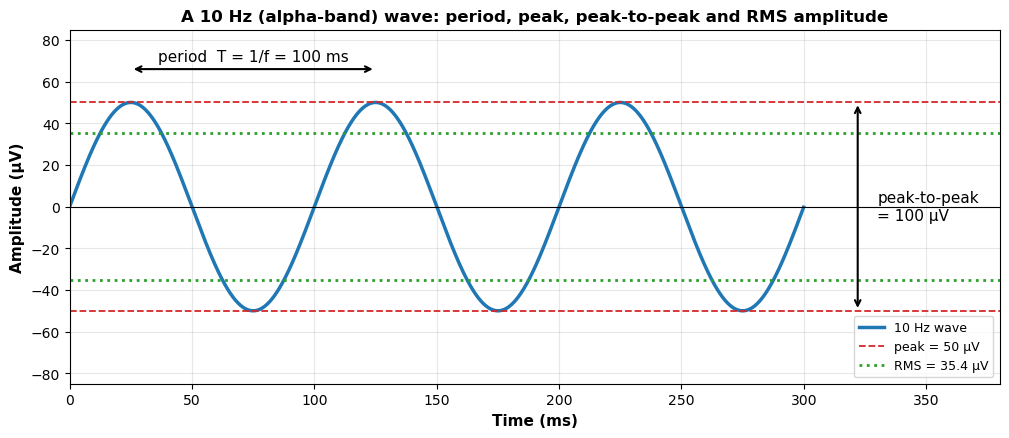

In [3]:
f0, A0 = 10, 50                    # a 10 Hz wave with 50 µV peak amplitude
t = time_vec(0.3, 10000)           # 0.3 s on a fine grid, so the curve looks smooth
x = sine(t, f0, A0)
T_ms = 1000 / f0

fig, ax = plt.subplots(figsize=(12, 4.6))
ax.plot(t * 1000, x, color=C_CARRIER, lw=2.5, label=f"{f0} Hz wave")
ax.axhline(0, color="k", lw=0.8)
ax.axhline(A0, color=C_MOD, ls="--", lw=1.3, label=f"peak = {A0} µV")
ax.axhline(-A0, color=C_MOD, ls="--", lw=1.3)
ax.axhline(A0 / np.sqrt(2), color=C_ENV, ls=":", lw=2, label=f"RMS = {A0 / np.sqrt(2):.1f} µV")
ax.axhline(-A0 / np.sqrt(2), color=C_ENV, ls=":", lw=2)

# period (time between two successive peaks)
ax.annotate("", xy=(25 + T_ms, 66), xytext=(25, 66), arrowprops=dict(arrowstyle="<->", color="k", lw=1.5))
ax.text(25 + T_ms / 2, 70, f"period  T = 1/f = {T_ms:.0f} ms", ha="center", fontsize=11)
# peak-to-peak (drawn to the right of the wave)
ax.annotate("", xy=(322, A0), xytext=(322, -A0), arrowprops=dict(arrowstyle="<->", color="k", lw=1.5))
ax.text(330, 0, f"peak-to-peak\n= {2 * A0} µV", va="center", fontsize=11)

ax.set_xlim(0, 380)
ax.set_ylim(-85, 85)
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Amplitude (µV)")
ax.set_title("A 10 Hz (alpha-band) wave: period, peak, peak-to-peak and RMS amplitude")
ax.legend(loc="lower right")
plt.show()

**Phase** tells you *where in its cycle* a wave is at a given moment. Two waves with the same frequency and
amplitude but different phase look like shifted copies of each other. Phase becomes important in section 8,
because some filters **shift the phase** of EEG waves — and a phase shift is a *time* shift.

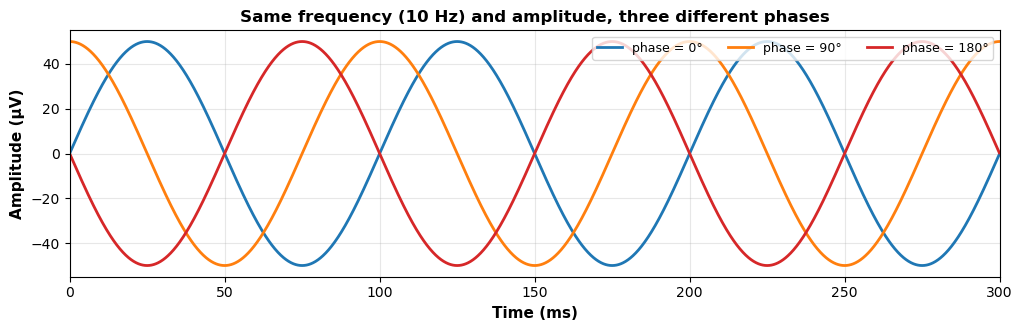

90° at 10 Hz = a quarter of a 100 ms period = 25 ms time shift.  180° = 50 ms.


In [4]:
fig, ax = plt.subplots(figsize=(12, 3.2))
for ph, c in zip([0, 90, 180], ["tab:blue", "tab:orange", "tab:red"]):
    ax.plot(t * 1000, sine(t, 10, 50, np.deg2rad(ph)), color=c, lw=2, label=f"phase = {ph}°")
ax.set_xlim(0, 300)
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Amplitude (µV)")
ax.set_title("Same frequency (10 Hz) and amplitude, three different phases")
ax.legend(loc="upper right", ncol=3)
plt.show()
print("90° at 10 Hz = a quarter of a 100 ms period = 25 ms time shift.  180° = 50 ms.")

**Try it yourself.** Move the sliders to see how frequency, amplitude and phase change the wave, and what
the wave looks like in the *frequency domain*: a single spike at the wave's frequency whose height is its amplitude.

In [ ]:
def explore_wave(freq=10.0, amp=50.0, phase_deg=0.0, duration=0.6):
    tt = time_vec(duration, 5000)
    xx = sine(tt, freq, amp, np.deg2rad(phase_deg))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw=dict(width_ratios=[3, 1]))
    a1.plot(tt * 1000, xx, color=C_CARRIER, lw=2)
    a1.set_ylim(-105, 105)
    a1.set_xlabel("Time (ms)")
    a1.set_ylabel("Amplitude (µV)")
    a1.set_title(f"T = {1000 / freq:.0f} ms | peak {amp:.0f} µV | peak-to-peak {2 * amp:.0f} µV | RMS {amp / np.sqrt(2):.1f} µV",
                 fontsize=10)
    a2.stem([freq], [amp], basefmt=" ")
    a2.set_xlim(0, 60)
    a2.set_ylim(0, 105)
    a2.set_xlabel("Frequency (Hz)")
    a2.set_ylabel("Amplitude (µV)")
    a2.set_title("Frequency domain")
    plt.show()


interact(explore_wave, freq=(0.5, 60.0, 0.5), amp=(1.0, 100.0, 1.0), phase_deg=(0, 360, 15), duration=(0.2, 2.0, 0.1));

## 3. The classic frequency bands

EEG researchers split the spectrum into named **bands**. The names and boundaries differ slightly between labs,
but the usual convention is:

| Band | Frequency | Typically associated with | Illustrative peak amplitude used here |
|---|---|---|---|
| **Delta (δ)** | 0.5–4 Hz | deep (slow-wave) sleep; in awake adults large slow waves can signal pathology or artifacts | 75 µV |
| **Theta (θ)** | 4–8 Hz | drowsiness, light sleep; frontal-midline theta during memory and cognitive effort | 40 µV |
| **Alpha (α)** | 8–13 Hz | relaxed wakefulness, especially eyes closed; strongest over the back of the head (visual cortex) | 30 µV |
| **Beta (β)** | 13–30 Hz | alertness, active thinking; sensorimotor rhythms | 12 µV |
| **Gamma (γ)** | 30–80+ Hz | local cortical processing, attention, perception; easily contaminated by muscle activity | 5 µV |

**A word of caution about the amplitude column.** The amplitudes are *illustrative*: chosen inside commonly
quoted ranges so the simulations look plausible. Real values depend on age, brain state, electrode position, and
on whether peak-to-peak or RMS is quoted. What *is* robust is the trend: **slower waves are larger, faster waves
are smaller.** The next cells show it, and section 4 explains it.

Below, each band is simulated twice, **on the same µV scale** so that sizes are directly comparable:
* **left:** a pure sine wave at one representative frequency — the textbook picture;
* **right:** *band-limited noise* with the same RMS — closer to what a real brain produces, because
  real rhythms are not perfectly regular: they wax, wane and wobble in frequency.

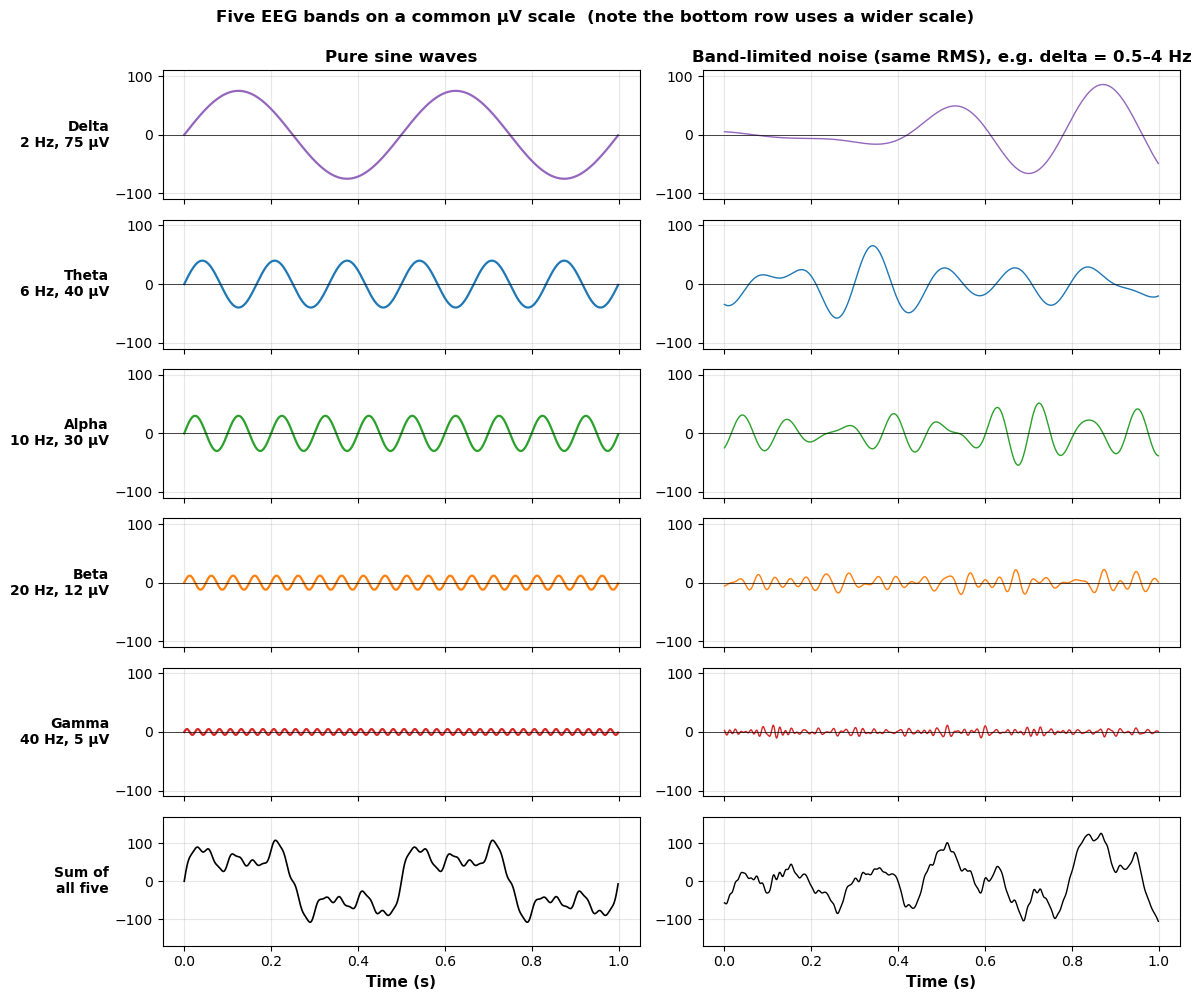

In [6]:
# name: (low Hz, high Hz, representative frequency Hz, illustrative peak amplitude µV, colour)
BANDS = {
    "Delta": (0.5, 4, 2, 75, "tab:purple"),
    "Theta": (4, 8, 6, 40, "tab:blue"),
    "Alpha": (8, 13, 10, 30, "tab:green"),
    "Beta": (13, 30, 20, 12, "tab:orange"),
    "Gamma": (30, 80, 40, 5, "tab:red"),
}

dur = 1.0
t = time_vec(dur)
n_long = int(20 * FS)  # generate 20 s of noise and show the first second
sines, noises = {}, {}
for name, (lo, hi, f_rep, amp, col) in BANDS.items():
    sines[name] = sine(t, f_rep, amp)
    box = lambda f, lo=lo, hi=hi: ((f >= lo) & (f <= hi)).astype(float)
    noises[name] = shaped_noise(n_long, FS, box, rms_uV=amp / np.sqrt(2), rng=rng)[: len(t)]

fig, axes = plt.subplots(len(BANDS) + 1, 2, figsize=(12, 10), sharex=True)
for row, (name, (lo, hi, f_rep, amp, col)) in enumerate(BANDS.items()):
    axes[row, 0].plot(t, sines[name], color=col, lw=1.6)
    axes[row, 1].plot(t, noises[name], color=col, lw=1.0)
    for a in axes[row]:
        a.set_ylim(-110, 110)
        a.axhline(0, color="k", lw=0.5)
    axes[row, 0].set_ylabel(f"{name}\n{f_rep} Hz, {amp} µV", rotation=0, ha="right", va="center", fontsize=10)
total_s, total_n = sum(sines.values()), sum(noises.values())
axes[-1, 0].plot(t, total_s, color="k", lw=1.2)
axes[-1, 1].plot(t, total_n, color="k", lw=1.0)
for a in axes[-1]:
    a.set_ylim(-170, 170)
    a.set_xlabel("Time (s)")
axes[-1, 0].set_ylabel("Sum of\nall five", rotation=0, ha="right", va="center", fontsize=10)
axes[0, 0].set_title("Pure sine waves")
axes[0, 1].set_title(f"Band-limited noise (same RMS), e.g. delta = {BANDS['Delta'][0]}–{BANDS['Delta'][1]} Hz")
fig.suptitle("Five EEG bands on a common µV scale  (note the bottom row uses a wider scale)", fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

Look at the left column: in one second the delta wave completes **2 cycles**, the gamma wave **40**, and the
delta wave is **15 times taller**. If you auto-scaled every trace separately they would all look alike — always
check the µV scale of an EEG plot before comparing wave sizes.

## 4. Amplitude versus frequency: the 1/f rule

The amplitude–frequency trend in the previous plot is not an accident. In real EEG the **power spectral density
(PSD)** falls off roughly as

$$\mathrm{PSD}(f)\;\propto\;\frac{1}{f^{\chi}}\qquad\text{with an exponent } \chi \text{ typically around 1–2}$$

On a log-log plot this is a **straight line with slope −χ**. Because power is amplitude squared, the amplitude of a single
frequency component (what an FFT amplitude spectrum shows) falls as $1/f^{\chi/2}$. For χ = 2 that is simply
**amplitude ∝ 1/f**: double the frequency, halve the amplitude.

Why? It is still debated. Commonly cited reasons are that slow oscillations can synchronise **larger populations**
of neurons than fast ones, and that dendrites and cell membranes behave like **low-pass filters**.

Why you should care:
* **Slow activity (and drift) dominates raw EEG**; gamma is tiny and easily swamped by muscle or line noise.
* Spectra must be plotted on **log axes** or you will see nothing but the low frequencies.
* A filter's effect depends on *where* in this steep spectrum its cutoff sits.

### 4.1 Noise "colours": the exponent χ
Three signals with the *same RMS* (20 µV) but different exponents: white (χ = 0), pink (χ = 1), brown (χ = 2).
I'll also fit the slope of each log-log spectrum between 2 and 100 Hz to confirm that it recovers −χ.

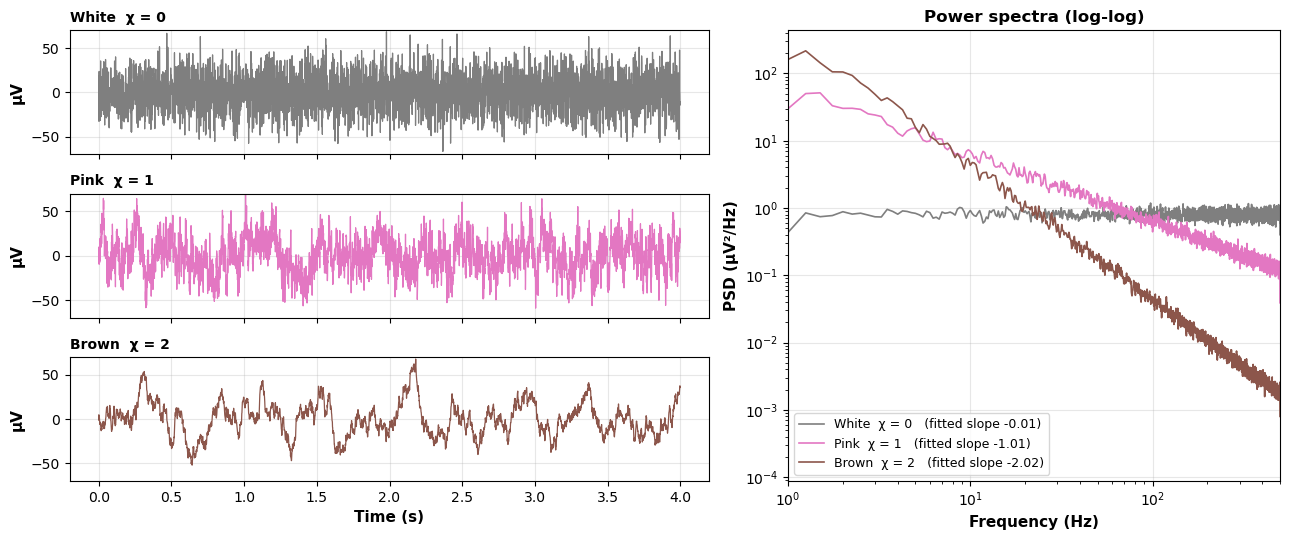

In [7]:
n = int(120 * FS)
colours = {0: ("White  χ = 0", "tab:gray"), 1: ("Pink  χ = 1", "tab:pink"), 2: ("Brown  χ = 2", "tab:brown")}
signals = {chi: pink_noise(n, FS, chi, rms_uV=20, rng=rng) for chi in colours}

fig = plt.figure(figsize=(13, 5.5))
gs = fig.add_gridspec(3, 2, width_ratios=[1.3, 1])
ax_psd = fig.add_subplot(gs[:, 1])
for i, (chi, (label, col)) in enumerate(colours.items()):
    ax = fig.add_subplot(gs[i, 0])
    tt = time_vec(4)
    ax.plot(tt, signals[chi][: len(tt)], color=col, lw=0.9)
    ax.set_ylim(-70, 70)
    ax.set_ylabel("µV")
    ax.set_title(label, fontsize=10, loc="left")
    if i < 2:
        ax.set_xticklabels([])
    f, p = welch_uV(signals[chi])
    sel = (f >= 2) & (f <= 100)
    slope = np.polyfit(np.log10(f[sel]), np.log10(p[sel]), 1)[0]
    ax_psd.loglog(f[1:], p[1:], color=col, lw=1.2, label=f"{label}   (fitted slope {slope:+.2f})")
ax.set_xlabel("Time (s)")
ax_psd.set_xlim(1, 500)
ax_psd.set_xlabel("Frequency (Hz)")
ax_psd.set_ylabel("PSD (µV²/Hz)")
ax_psd.set_title("Power spectra (log-log)")
ax_psd.legend(loc="lower left")
plt.tight_layout()
plt.show()

### 4.2 Our five band waves follow the same trend
Here are the five illustrative waves of section 3 as points (frequency, peak amplitude) on log-log axes, with the
slope fitted through them.

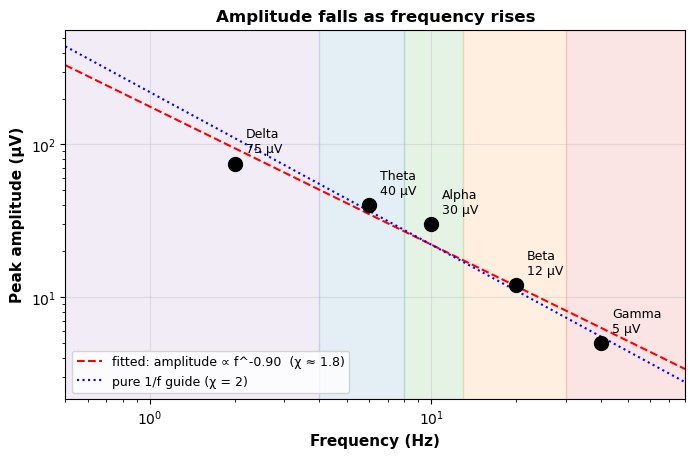

Fitted exponent chi = 1.81 (amplitude ∝ f^-0.90).
The amplitudes were picked by hand to look plausible, so landing in the usual 1-2 range is a sanity check, not a measurement.


In [8]:
f_rep = np.array([v[2] for v in BANDS.values()], dtype=float)
amps = np.array([v[3] for v in BANDS.values()], dtype=float)
slope, intercept = np.polyfit(np.log10(f_rep), np.log10(amps), 1)
chi_est = -2 * slope  # amplitude ∝ f^(-chi/2)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.loglog(f_rep, amps, "o", ms=10, color="k", zorder=3)
for name, (lo, hi, fr, amp, col) in BANDS.items():
    ax.axvspan(lo, hi, color=col, alpha=0.12)
    ax.annotate(f"{name}\n{amp} µV", (fr, amp), textcoords="offset points", xytext=(8, 8), fontsize=9)
ff = np.logspace(np.log10(0.5), np.log10(80), 50)
ax.loglog(ff, 10 ** intercept * ff ** slope, "r--", lw=1.5, label=f"fitted: amplitude ∝ f^{slope:.2f}  (χ ≈ {chi_est:.1f})")
ax.loglog(ff, 10 ** np.mean(np.log10(amps * f_rep)) / ff, "b:", lw=1.5, label="pure 1/f guide (χ = 2)")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Peak amplitude (µV)")
ax.set_title("Amplitude falls as frequency rises")
ax.legend(loc="lower left")
ax.set_xlim(0.5, 80)
plt.show()
print(f"Fitted exponent chi = {chi_est:.2f} (amplitude ∝ f^{slope:.2f}).")
print("The amplitudes were picked by hand to look plausible, so landing in the usual 1-2 range is a sanity check, not a measurement.")

### 4.3 Real spectra = a 1/f background plus rhythmic peaks
Modern spectral analysis (e.g. the *specparam / FOOOF* approach) treats an EEG spectrum as two ingredients:
a smooth **aperiodic** 1/f background and **periodic** peaks — rhythms such as alpha — standing out above it.
Let's build exactly that: 1/f noise (χ = 1.5) plus a narrowband 10 Hz rhythm.

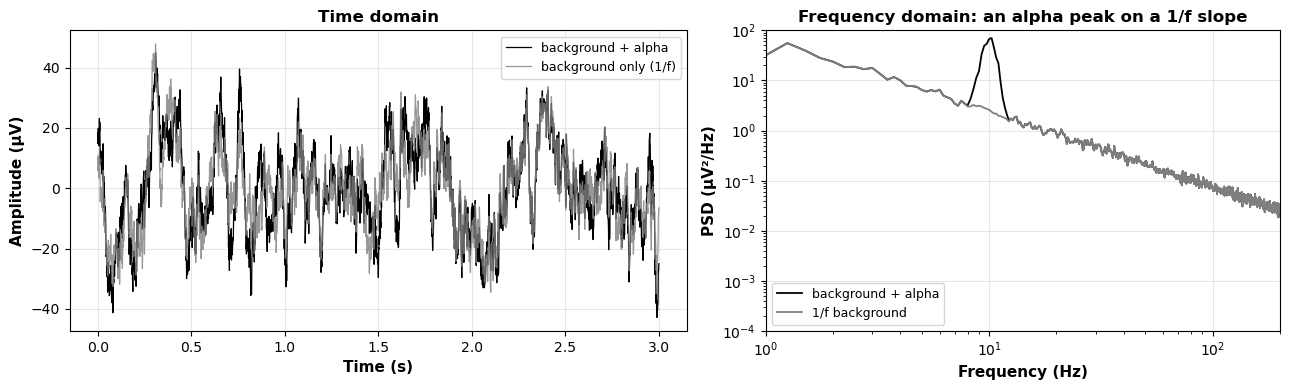

In [9]:
n = int(120 * FS)
background = pink_noise(n, FS, 1.5, rms_uV=12, rng=rng)
alpha_rhythm = narrowband_noise(n, FS, f0=10, bw=0.8, rms_uV=10, rng=rng)
eeg_like = background + alpha_rhythm

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw=dict(width_ratios=[1.2, 1]))
tt = time_vec(3)
a1.plot(tt, eeg_like[: len(tt)], "k", lw=0.9, label="background + alpha")
a1.plot(tt, background[: len(tt)], color="tab:gray", lw=0.9, alpha=0.8, label="background only (1/f)")
a1.set_xlabel("Time (s)")
a1.set_ylabel("Amplitude (µV)")
a1.set_title("Time domain")
a1.legend(loc="upper right")
f, p_all = welch_uV(eeg_like)
_, p_bg = welch_uV(background)
a2.loglog(f[1:], p_all[1:], "k", lw=1.3, label="background + alpha")
a2.loglog(f[1:], p_bg[1:], color="tab:gray", lw=1.3, label="1/f background")
a2.set_xlim(1, 200)
a2.set_ylim(1e-4, 1e2)
a2.set_xlabel("Frequency (Hz)")
a2.set_ylabel("PSD (µV²/Hz)")
a2.set_title("Frequency domain: an alpha peak on a 1/f slope")
a2.legend(loc="lower left")
plt.tight_layout()
plt.show()

### 4.4 Units cheat-sheet (and a sanity check)

| Quantity | Unit | Meaning |
|---|---|---|
| Amplitude | µV | size of a wave (peak, peak-to-peak or RMS — say which!) |
| Power | µV² | mean squared amplitude (= the variance of the signal) |
| Power spectral density (PSD) | µV²/Hz | power *per Hz of bandwidth* — the standard "spectrum" |
| Amplitude spectral density | µV/√Hz | square root of the PSD |
| Decibel | dB | 10·log₁₀(power / reference power), e.g. relative to 1 µV²/Hz |

The PSD is a *density*: integrate (sum × Δf) it over all frequencies and you get back the total power.
A quick numerical check with a 10 Hz sine of 30 µV peak amplitude:

In [10]:
x = sine(time_vec(10), 10, 30)
f, p = welch_uV(x)
df = f[1] - f[0]
print(f"peak amplitude   : {np.max(np.abs(x)):6.2f} µV")
print(f"peak-to-peak     : {np.ptp(x):6.2f} µV")
print(f"RMS amplitude    : {rms(x):6.2f} µV   (theory: 30/√2 = {30 / np.sqrt(2):.2f})")
print(f"power (variance) : {np.var(x):6.1f} µV²  (theory: 30²/2 = {30 ** 2 / 2:.0f})")
print(f"area under PSD   : {np.sum(p) * df:6.1f} µV²  <- the PSD integrates back to the power")
print(f"power in dB      : {10 * np.log10(np.var(x)):6.1f} dB re 1 µV²")

peak amplitude   :  30.00 µV
peak-to-peak     :  60.00 µV
RMS amplitude    :  21.21 µV   (theory: 30/√2 = 21.21)
power (variance) :  450.0 µV²  (theory: 30²/2 = 450)
area under PSD   :  450.0 µV²  <- the PSD integrates back to the power
power in dB      :   26.5 dB re 1 µV²


## 5. Modulated oscillations (in the style of `sine_models.ipynb`)

Real EEG rhythms are rarely constant. A fast rhythm's **amplitude** can be steered by a slower one — for
instance gamma amplitude rising and falling with the phase of a theta rhythm (*phase–amplitude coupling*, a kind of
cross-frequency coupling). In **frequency-tagging** experiments, brain responses follow the modulation of a stimulus.
The simplest model of this is **amplitude modulation (AM)**: a slow *modulator* sets the *envelope* of a fast *carrier*:

$$\text{signal}(t) = \text{envelope}(t)\times\text{carrier}(t),\qquad \text{envelope}=\frac{1+\text{modulator}}{2}\in[0,1]$$

This section re-implements the construction used in `sine_models.ipynb` (carrier → modulator → envelope → modulated
signal; 60 Hz × 20 Hz and 150 Hz × 30 Hz), but in **µV**, sampled like a real EEG, and with one extra view:
the **spectrum**. (`sine_models.ipynb` itself is left untouched; this is a separate re-implementation.)

In each time-domain panel the **faint line is the "analog" signal** (computed at 10 kHz) and the **stepped line with
dots is what the recording keeps** at the EEG sampling rate `FS`.

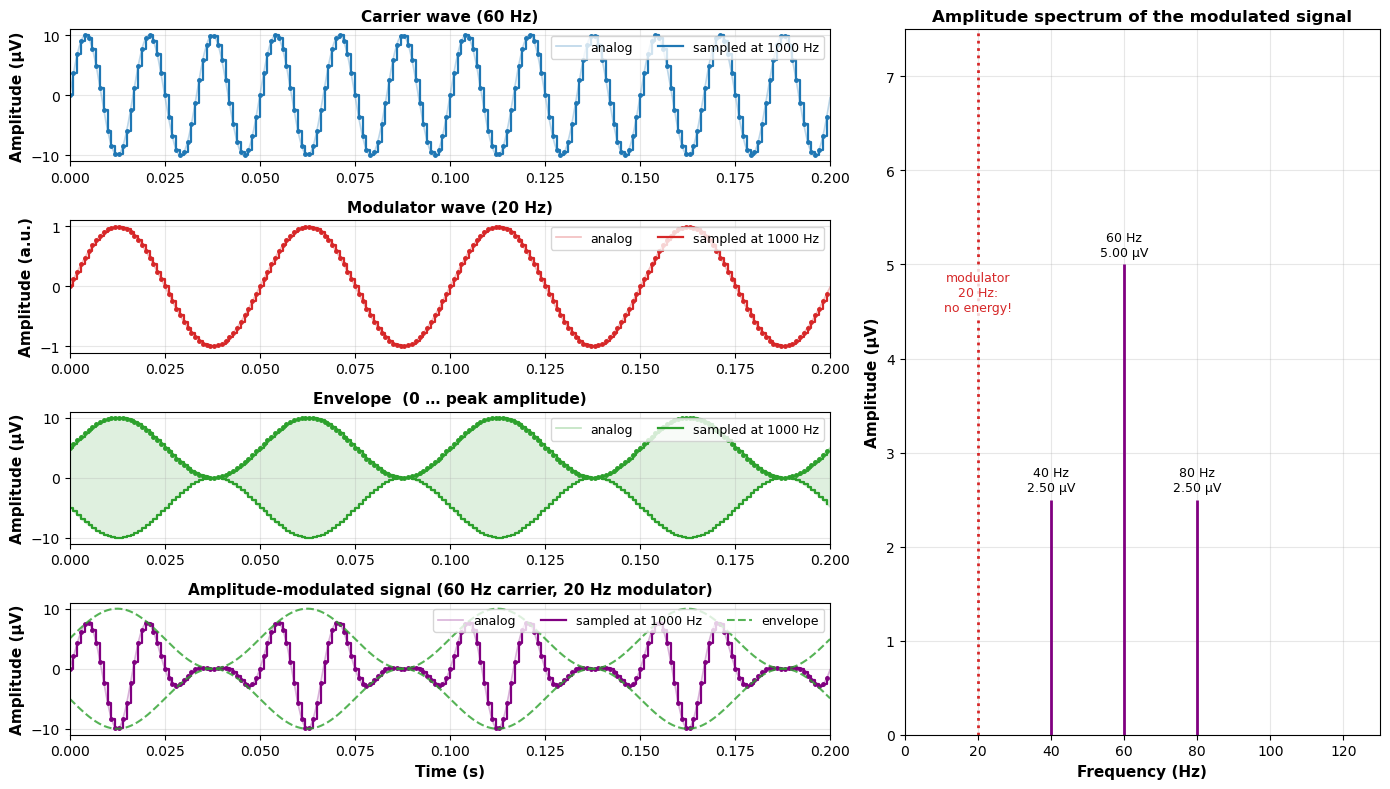

In [11]:
def am_signal(t, carrier_freq, modulator_freq, amp_uV=10.0, depth=1.0, carrier_phase=0.0, modulator_phase=0.0):
    """Amplitude-modulated signal as in sine_models.ipynb. depth=1 gives envelope = (modulator + 1) / 2 exactly."""
    carrier = np.sin(2 * np.pi * carrier_freq * t + carrier_phase)
    modulator = np.sin(2 * np.pi * modulator_freq * t + modulator_phase)
    envelope = (1 + depth * modulator) / (1 + depth)  # unitless, ranges from (1-depth)/(1+depth) up to 1
    return dict(carrier=amp_uV * carrier, modulator=modulator, envelope=amp_uV * envelope, am=amp_uV * envelope * carrier)


def am_expected_lines(carrier_freq, modulator_freq, amp_uV=10.0, depth=1.0):
    """Spectral lines of the AM signal: (frequency, amplitude in µV)."""
    return [(carrier_freq - modulator_freq, amp_uV * depth / (2 * (1 + depth))),
            (carrier_freq, amp_uV / (1 + depth)),
            (carrier_freq + modulator_freq, amp_uV * depth / (2 * (1 + depth)))]


def plot_am(carrier_freq=60, modulator_freq=20, amp_uV=10, depth=1.0, duration=0.2, fs=FS, fs_smooth=10000):
    t_s = time_vec(duration, fs_smooth)   # "analog" time axis
    t_d = time_vec(duration, fs)          # time axis of the recording
    ana, dig = am_signal(t_s, carrier_freq, modulator_freq, amp_uV, depth), am_signal(t_d, carrier_freq, modulator_freq, amp_uV, depth)

    fig = plt.figure(figsize=(14, 8))
    gs = fig.add_gridspec(4, 2, width_ratios=[1.6, 1])
    axes = [fig.add_subplot(gs[i, 0]) for i in range(4)]
    spec_ax = fig.add_subplot(gs[:, 1])

    spec = [("carrier", C_CARRIER, f"Carrier wave ({carrier_freq} Hz)", "Amplitude (µV)"),
            ("modulator", C_MOD, f"Modulator wave ({modulator_freq} Hz)", "Amplitude (a.u.)"),
            ("envelope", C_ENV, "Envelope  (0 … peak amplitude)", "Amplitude (µV)"),
            ("am", C_AM, f"Amplitude-modulated signal ({carrier_freq} Hz carrier, {modulator_freq} Hz modulator)", "Amplitude (µV)")]
    for ax, (key, col, title, ylab) in zip(axes, spec):
        ax.plot(t_s, ana[key], color=col, lw=1.2, alpha=0.3, label="analog")
        ax.step(t_d, dig[key], where="post", color=col, lw=1.6, label=f"sampled at {fs} Hz")
        ax.plot(t_d, dig[key], "o", color=col, ms=2.5)
        if key == "envelope":
            ax.step(t_d, -dig[key], where="post", color=col, lw=1.6)
            ax.fill_between(t_s, -ana[key], ana[key], color=col, alpha=0.15)
        if key == "am":
            ax.plot(t_s, ana["envelope"], "--", color=C_ENV, lw=1.5, alpha=0.8, label="envelope")
            ax.plot(t_s, -ana["envelope"], "--", color=C_ENV, lw=1.5, alpha=0.8)
        ax.set_xlim(0, duration)
        ax.set_ylabel(ylab)
        ax.set_title(title, fontsize=11)
        ax.legend(loc="upper right", ncol=3)
    axes[-1].set_xlabel("Time (s)")

    # spectrum of the *sampled* signal (2 s of data -> exact frequency bins for integer frequencies)
    t_spec = time_vec(2.0, fs)
    x = am_signal(t_spec, carrier_freq, modulator_freq, amp_uV, depth)["am"]
    freqs = np.fft.rfftfreq(len(x), 1 / fs)
    amp_spec = 2 * np.abs(np.fft.rfft(x)) / len(x)
    spec_ax.vlines(freqs, 0, amp_spec, color=C_AM, lw=2)
    spec_ax.set_xlim(0, min(fs / 2, carrier_freq + 2.5 * modulator_freq + 20))
    spec_ax.set_ylim(0, amp_uV * 0.75)
    for fl, al in am_expected_lines(carrier_freq, modulator_freq, amp_uV, depth):
        if al > 0:
            spec_ax.annotate(f"{fl:g} Hz\n{al:.2f} µV", (fl, al), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=9)
    spec_ax.axvline(modulator_freq, color=C_MOD, ls=":", lw=2)
    spec_ax.text(modulator_freq, 0.45 * amp_uV, f"modulator\n{modulator_freq} Hz:\nno energy!", color=C_MOD,
                 ha="center", fontsize=9, bbox=dict(fc="white", ec="none", alpha=0.8))
    spec_ax.set_xlabel("Frequency (Hz)")
    spec_ax.set_ylabel("Amplitude (µV)")
    spec_ax.set_title("Amplitude spectrum of the modulated signal")
    plt.tight_layout()
    plt.show()


plot_am(carrier_freq=60, modulator_freq=20)

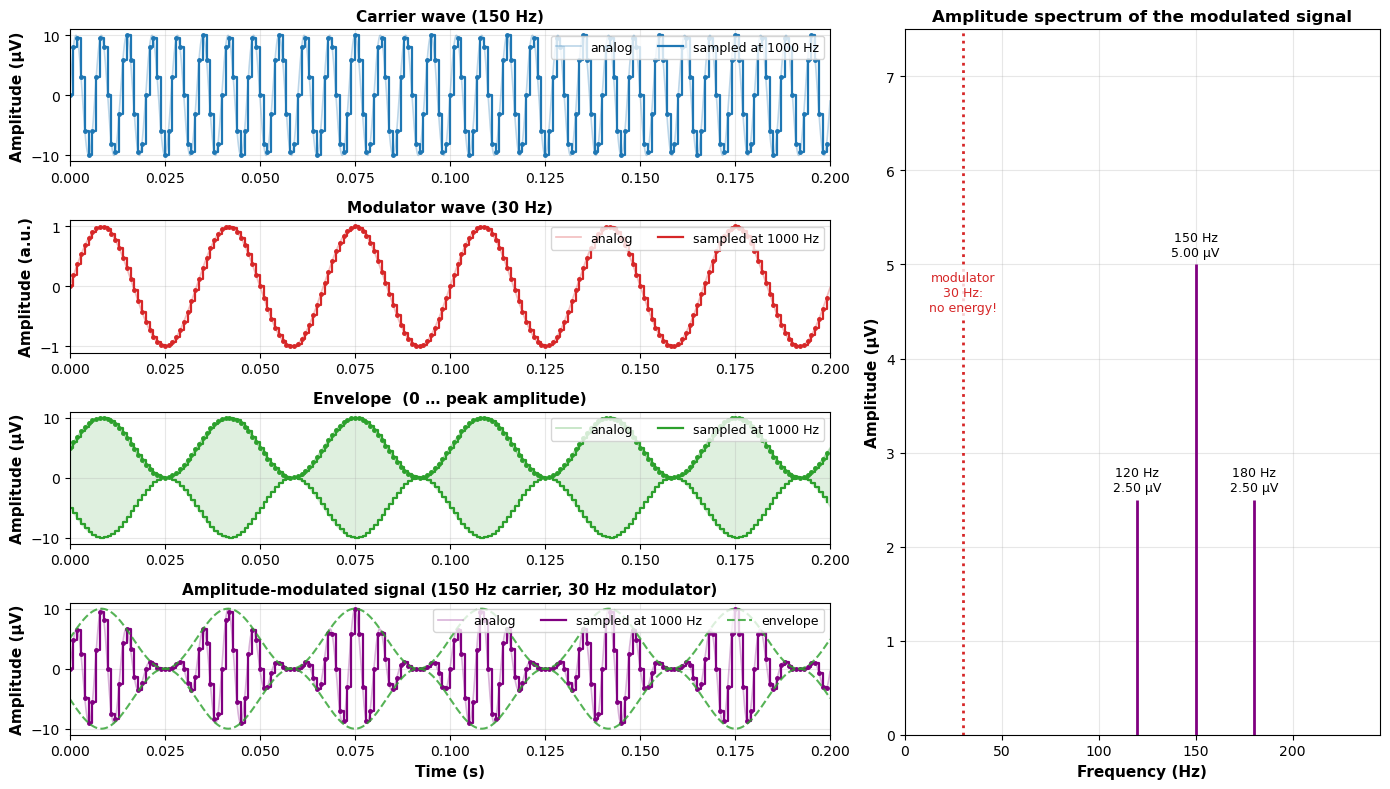

In [12]:
plot_am(carrier_freq=150, modulator_freq=30)

### What the spectrum reveals
A 60 Hz carrier modulated at 20 Hz does **not** contain a 20 Hz component. Mathematically
$\tfrac12 c + \tfrac12 m\,c$ with $m\,c=\tfrac12[\cos(f_c-f_m)-\cos(f_c+f_m)]$, so the signal consists of exactly **three
spectral lines**: the carrier ($f_c$, amplitude ½ of the peak) and two **sidebands** at $f_c \pm f_m$ (¼ each).
The envelope is a *beat pattern* between those three lines, not a frequency of its own.

This has direct consequences for filtering (section 8):
* a **low-pass at 30 Hz** would remove *all three* lines — the whole signal disappears, including the 20 Hz "rhythm";
* a **narrow band-pass around the carrier** keeps the carrier but discards the sidebands, and the **modulation vanishes**;
* a **notch** at the mains frequency (50/60 Hz) sits right on top of — or next to — a 60 Hz carrier.

### Sampling rate: how fast must we sample?
Sampling at `fs` Hz can only represent frequencies **below fs/2** (the *Nyquist frequency*). Higher frequencies
don't vanish — they **fold back (alias)** to a lower, wrong frequency. The 150 Hz × 30 Hz signal contains energy at
120, 150 and **180 Hz**, so it needs `fs` > 360 Hz. Below: the same signal sampled at 1440 Hz, 480 Hz and 250 Hz
*without* any anti-aliasing filter (the rates echo the refresh rates in `sine_models.ipynb`).

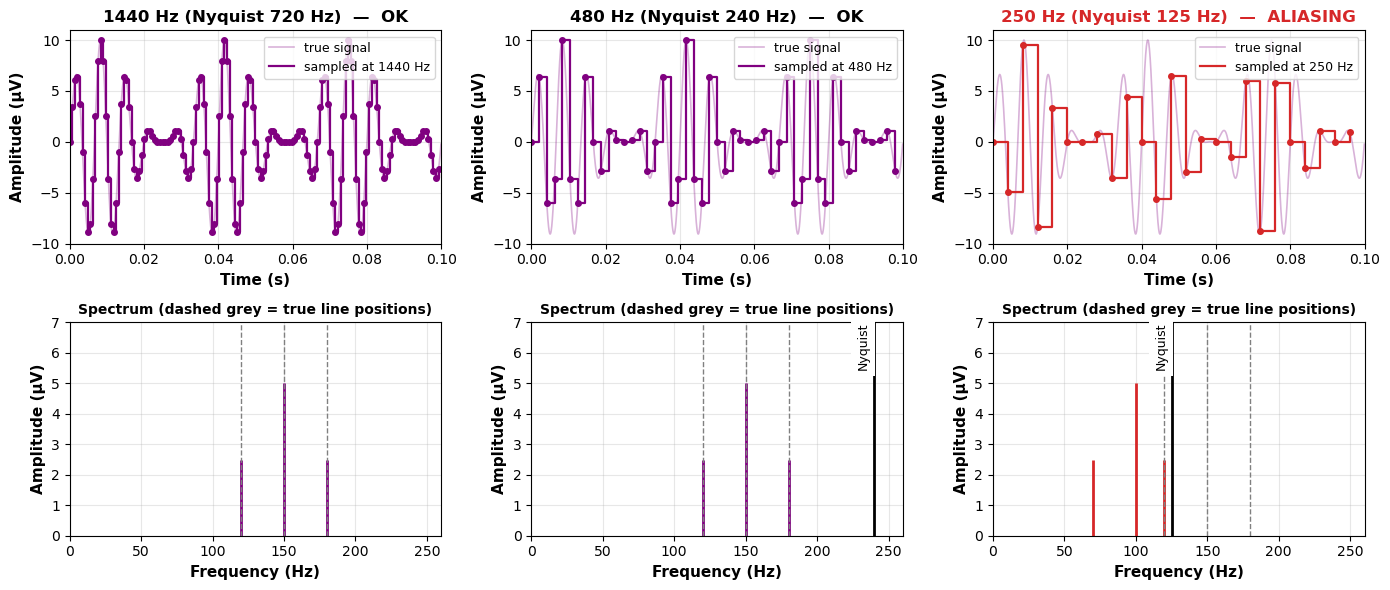

fs = 1440 Hz:  true lines at 120, 150, 180 Hz  ->  appear at 120, 150, 180 Hz
fs =  480 Hz:  true lines at 120, 150, 180 Hz  ->  appear at 120, 150, 180 Hz
fs =  250 Hz:  true lines at 120, 150, 180 Hz  ->  appear at 120, 100, 70 Hz


In [13]:
def alias_freq(f, fs):
    """Frequency at which a pure tone of f Hz appears after (naive) sampling at fs Hz."""
    return abs(f - fs * np.round(f / fs))


def sampling_demo(carrier_freq=150, modulator_freq=30, rates=(1440, 480, 250), amp_uV=10, duration=0.1):
    true_lines = [fl for fl, _ in am_expected_lines(carrier_freq, modulator_freq, amp_uV)]
    t_s = time_vec(duration, 20000)
    ana = am_signal(t_s, carrier_freq, modulator_freq, amp_uV)["am"]
    fig, axes = plt.subplots(2, len(rates), figsize=(14, 6))
    for j, r in enumerate(rates):
        t_d = np.arange(0, duration, 1 / r)
        x_d = am_signal(t_d, carrier_freq, modulator_freq, amp_uV)["am"]
        ok = r / 2 > max(true_lines)
        col = C_AM if ok else "tab:red"
        ax = axes[0, j]
        ax.plot(t_s, ana, color=C_AM, lw=1.2, alpha=0.3, label="true signal")
        ax.step(t_d, x_d, where="post", color=col, lw=1.6, label=f"sampled at {r} Hz")
        ax.plot(t_d, x_d, "o", color=col, ms=4)
        ax.set_xlim(0, duration)
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Amplitude (µV)")
        ax.set_title(f"{r} Hz (Nyquist {r / 2:g} Hz)  —  " + ("OK" if ok else "ALIASING"), color="k" if ok else "tab:red")
        ax.legend(loc="upper right")

        t_spec = np.arange(0, 2.0, 1 / r)
        xs = am_signal(t_spec, carrier_freq, modulator_freq, amp_uV)["am"]
        fr = np.fft.rfftfreq(len(xs), 1 / r)
        sp = 2 * np.abs(np.fft.rfft(xs)) / len(xs)
        ax = axes[1, j]
        ax.vlines(fr, 0, sp, color=col, lw=2)
        for fl in true_lines:
            ax.axvline(fl, color="gray", ls="--", lw=1)
        ax.set_xlim(0, 260)
        if r / 2 <= 260:  # only draw the Nyquist marker if it falls inside the plotted range
            ax.axvline(r / 2, color="k", lw=2)
            ax.text(r / 2 - 3, amp_uV * 0.62, "Nyquist", ha="right", va="center", rotation=90, fontsize=9,
                    bbox=dict(fc="white", ec="none"))
        ax.set_ylim(0, amp_uV * 0.7)
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel("Amplitude (µV)")
        ax.set_title("Spectrum (dashed grey = true line positions)", fontsize=10)
    plt.tight_layout()
    plt.show()
    for r in rates:
        seen = ", ".join(f"{alias_freq(f, r):g}" for f in true_lines)
        print(f"fs = {r:4d} Hz:  true lines at {', '.join(f'{f:g}' for f in true_lines)} Hz  ->  appear at {seen} Hz")


sampling_demo()

At 250 Hz (Nyquist = 125 Hz) the 150 Hz carrier shows up at **100 Hz** and the 180 Hz sideband at **70 Hz**: the
recording contains a pattern that was never there. Two practical notes:
* Real EEG amplifiers apply an **analog anti-aliasing low-pass filter** before sampling, so you will not see this in
  a recording — but you *can* create it yourself by **down-sampling carelessly**. (MNE's `raw.resample()` filters first.)
* The same arithmetic applies to the stepped "refresh-rate" versions in `sine_models.ipynb`: a 480 Hz refresh rate
  can only represent frequencies below 240 Hz.

This is why the recordings in this notebook use **FS = 1000 Hz**: it comfortably covers the 180 Hz sideband and
leaves room for the gamma band and for muscle noise.

**Try it yourself.** Change carrier, modulator and modulation *depth* (depth 0 = no modulation, depth 1 = the full
0…1 envelope used in `sine_models.ipynb`) and watch the three spectral lines move and change height.

In [ ]:
interact(plot_am, carrier_freq=(20, 200, 5), modulator_freq=(2, 60, 1), amp_uV=(2, 40, 1), depth=(0.0, 1.0, 0.1),
         duration=fixed(0.2), fs=fixed(FS), fs_smooth=fixed(10000));

## 6. A complete simulated EEG recording

Now we combine everything into a realistic **6-channel, 120-second recording** at 1000 Hz. The crucial design
decision: every ingredient is simulated **separately** and then summed, so we always know the ground truth.

| Ingredient | Model | Where it shows up | Size |
|---|---|---|---|
| **1/f background** | pink noise, exponent χ = 1.5 | everywhere | RMS 10 µV |
| **Theta** | narrowband noise at 6 Hz | frontal midline (Fz) | RMS 6 µV at its strongest channel |
| **Alpha** | narrowband noise at 10 Hz | occipital / parietal (O1, Pz) | RMS 15 µV |
| **Beta** | narrowband noise at 20 Hz | central (Cz) | RMS 3.5 µV |
| **ERP** | N1 (−4 µV, 100 ms), P3 (+9 µV, 320 ms), slow wave (+4 µV, 700 ms); ~50 trials, ±20 % amplitude jitter | fronto-central / parietal | few µV |
| **Line noise** | mains frequency plus two harmonics | everywhere | 8, 2 and 1 µV |
| **Slow drift** | slow sines (0.04, 0.12, 0.3 Hz) | everywhere | tens of µV |
| **Eye blinks** | ~100 ms Gaussian bumps every 2.5–6 s | frontal (Fp1) | 80–140 µV |
| **Muscle (EMG)** | bursts of 30–250 Hz noise | temporal (T7) | up to ~18 µV RMS |
| **Amplifier noise** | white noise | everywhere | 0.5 µV RMS |

The first five rows are the "**brain**" signal we would like to keep; the rest are **noise and artifacts** we would
like to remove. (Each row is multiplied by a per-channel weight that mimics scalp topography — e.g. alpha is strongest at the
back of the head.)

*Out of scope here:* MNE can also simulate EEG from **brain sources** through a head model
(`mne.simulation.simulate_raw`, `simulate_sparse_stc`). That needs a forward model and is a different topic; for
studying filters, simulating at the sensor level, as we do here, is exactly what we need.

In [15]:
CH_NAMES = ["Fp1", "Fz", "Cz", "Pz", "O1", "T7"]
N_CH = len(CH_NAMES)

# Spatial weights: how strongly each source appears at each channel (1 = strongest)
#                        Fp1   Fz    Cz    Pz    O1    T7
W_THETA = np.array([0.4, 1.0, 0.8, 0.5, 0.2, 0.4])      # frontal midline
W_ALPHA = np.array([0.2, 0.3, 0.5, 0.9, 1.0, 0.4])      # occipital / parietal
W_BETA = np.array([0.4, 0.6, 1.0, 0.6, 0.3, 0.6])       # central
W_BLINK = np.array([1.0, 0.5, 0.2, 0.05, 0.02, 0.15])   # frontal (close to the eyes)
W_EMG = np.array([0.3, 0.2, 0.2, 0.1, 0.1, 1.0])        # temporal (jaw muscles)

# ERP components: name -> (peak amplitude µV, latency s, width s, channel weights)
ERP_COMPONENTS = {
    "N1": (-4.0, 0.100, 0.020, np.array([0.3, 1.0, 1.0, 0.5, 0.3, 0.3])),
    "P3": (9.0, 0.320, 0.070, np.array([0.1, 0.5, 0.8, 1.0, 0.3, 0.2])),
    "Slow wave": (4.0, 0.700, 0.180, np.array([0.1, 0.4, 0.7, 1.0, 0.5, 0.2])),
}


def erp_truth(tau):
    """The noise-free ERP (channels x len(tau), µV) at times `tau` (s) relative to stimulus onset."""
    out = np.zeros((N_CH, len(tau)))
    for amp, lat, sd, w in ERP_COMPONENTS.values():
        out += w[:, None] * amp * np.exp(-0.5 * ((tau - lat) / sd) ** 2)[None, :]
    return out


def simulate_eeg(duration=120.0, fs=FS, seed=SEED, line_freq=LINE_FREQ):
    """Simulate a 6-channel EEG recording. Returns a dict that keeps every component separate (all in µV)."""
    r = np.random.default_rng(seed)
    n = int(round(duration * fs))
    t = np.arange(n) / fs
    c = {}  # components, in the order we want to display them

    # ---- brain activity -------------------------------------------------------------------------------------
    c["1/f background"] = np.array([pink_noise(n, fs, 1.5, 10.0, r, fmin=1.0) for _ in range(N_CH)])
    c["theta"] = W_THETA[:, None] * narrowband_noise(n, fs, 6, 0.8, 6.0, r)
    c["alpha"] = W_ALPHA[:, None] * narrowband_noise(n, fs, 10, 0.8, 15.0, r)
    c["beta"] = W_BETA[:, None] * narrowband_noise(n, fs, 20, 2.5, 3.5, r)

    tau = np.arange(int(-0.5 * fs), int(1.5 * fs)) / fs        # wide window so the Gaussians fade out completely
    template = erp_truth(tau)
    onsets, t_on = [], 3.0
    while t_on < duration - 1.6:
        onsets.append(int(round(t_on * fs)))
        t_on += r.uniform(2.0, 2.6)
    erp = np.zeros((N_CH, n))
    for o in onsets:
        i0 = o + int(-0.5 * fs)
        erp[:, i0:i0 + len(tau)] += r.normal(1.0, 0.2) * template  # single trials vary in size
    c["ERP"] = erp

    # ---- noise and artifacts --------------------------------------------------------------------------------
    line = np.zeros((N_CH, n))
    for mult, a in [(1, 8.0), (2, 2.0), (3, 1.0)]:               # mains and its harmonics
        ph, sc = r.uniform(0, 2 * np.pi, N_CH), r.uniform(0.8, 1.2, N_CH)
        line += a * sc[:, None] * np.sin(2 * np.pi * line_freq * mult * t[None, :] + ph[:, None])
    c["line noise"] = line

    drift = np.zeros((N_CH, n))
    for f_d, a_d in [(0.04, 40.0), (0.12, 15.0), (0.30, 6.0)]:
        ph, sc = r.uniform(0, 2 * np.pi, N_CH), r.uniform(0.5, 1.5, N_CH)
        drift += a_d * sc[:, None] * np.sin(2 * np.pi * f_d * t[None, :] + ph[:, None])
    c["slow drift"] = drift

    blink = np.zeros(n)
    blink_times, tb = [], 2.0
    tt = np.arange(int(-0.4 * fs), int(0.4 * fs)) / fs
    shape = np.exp(-0.5 * (tt / 0.06) ** 2)
    while tb < duration - 1.0:
        i0 = int(round(tb * fs)) + int(-0.4 * fs)
        blink[i0:i0 + len(tt)] += r.uniform(80, 140) * shape
        blink_times.append(tb)
        tb += r.uniform(2.5, 6.0)
    c["eye blinks"] = W_BLINK[:, None] * blink

    emg_noise = shaped_noise(n, fs, lambda f: ((f >= 30) & (f <= 250)).astype(float), 1.0, r)
    env, emg_times = np.zeros(n), []
    for _ in range(6):
        d = r.uniform(0.6, 1.6)
        st = r.uniform(2.0, duration - d - 1.0)
        i0, m = int(st * fs), int(d * fs)
        env[i0:i0 + m] += np.hanning(m)
        emg_times.append((st, st + d))
    c["muscle (EMG)"] = W_EMG[:, None] * 18.0 * emg_noise[None, :] * env[None, :]

    c["amplifier noise"] = 0.5 * r.standard_normal((N_CH, n))

    brain_names = ["1/f background", "theta", "alpha", "beta", "ERP"]
    brain = sum(c[k] for k in brain_names)
    artifacts = sum(v for k, v in c.items() if k not in brain_names)
    events = np.c_[onsets, np.zeros(len(onsets), int), np.ones(len(onsets), int)]  # MNE event array: [sample, 0, id]
    return dict(t=t, fs=fs, comp=c, brain=brain, artifacts=artifacts, eeg=brain + artifacts, events=events,
                blink_times=np.array(blink_times), emg_times=emg_times, tau=tau)


sim = simulate_eeg()
raw = make_raw(sim["eeg"], CH_NAMES)       # <- the object MNE works with (note: converted to volts inside)
raw.set_montage("standard_1020", verbose=False)   # electrode positions from the international 10-20 system
events = sim["events"]
print(raw)
print(f"{len(events)} stimulus events, {len(sim['blink_times'])} blinks, {len(sim['emg_times'])} muscle bursts")
print("Overall RMS per channel (µV):", {ch: round(float(v), 1) for ch, v in zip(CH_NAMES, rms(sim['eeg']))})

<RawArray | 6 x 120000 (120.0 s), ~5.5 MiB, data loaded>
51 stimulus events, 29 blinks, 6 muscle bursts
Overall RMS per channel (µV): {'Fp1': 40.9, 'Fz': 35.2, 'Cz': 42.1, 'Pz': 32.5, 'O1': 43.3, 'T7': 23.5}


### 6.1 What the recording looks like
Ten seconds of all six channels. The dashed vertical lines mark stimulus onsets. Look for: the large **blinks**
on Fp1, the 10 Hz **alpha** at the back (O1, Pz), a burst of **muscle** noise on T7, and the **slow drift** that
makes traces wander up and down. The ERP (a few µV) is completely invisible in single trials.

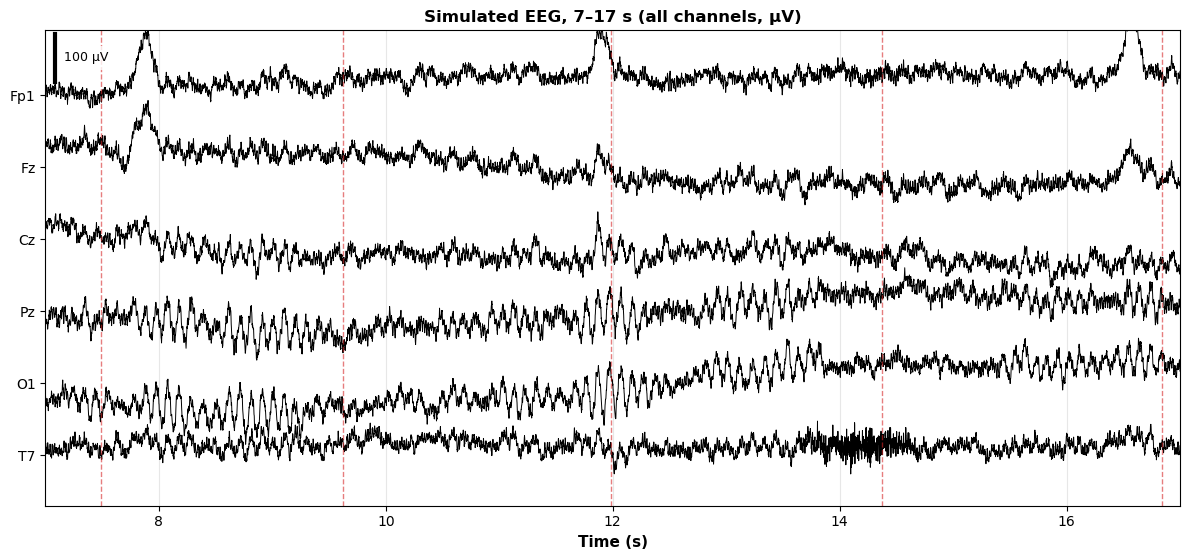

In [16]:
def best_window(sim, length=10.0):
    """Start time of a `length`-second window containing blinks, a muscle burst and a few stimuli."""
    onset_s = sim["events"][:, 0] / sim["fs"]
    best, t0_best = -1, 5.0
    for t0 in np.arange(5.0, sim["t"][-1] - length - 1, 0.5):
        nb = np.sum((sim["blink_times"] >= t0) & (sim["blink_times"] <= t0 + length))
        ne = sum(a <= t0 + length and b >= t0 for a, b in sim["emg_times"])
        no = np.sum((onset_s >= t0) & (onset_s <= t0 + length))
        score = min(nb, 3) + 3 * min(ne, 1) + min(no, 3)
        if score > best:
            best, t0_best = score, t0
    return t0_best


T0 = best_window(sim)
WIN = (T0, T0 + 10)
sl = slice(int(WIN[0] * FS), int(WIN[1] * FS))
ax = stack_plot(sim["eeg"][:, sl], sim["t"][sl], CH_NAMES, spacing=150, scale_bar=100,
                title=f"Simulated EEG, {WIN[0]:.0f}–{WIN[1]:.0f} s (all channels, µV)")
for o in sim["events"][:, 0] / FS:
    if WIN[0] <= o <= WIN[1]:
        ax.axvline(o, color="tab:red", ls="--", lw=1, alpha=0.6)
plt.tight_layout()
plt.show()

### 6.2 Taking the recording apart
Because we simulated each ingredient separately, we can look at them one by one for a single channel (Fz).
Note that each row has **its own µV scale** (the RMS is printed on the left) — the ingredients differ in size by
more than a factor of ten.

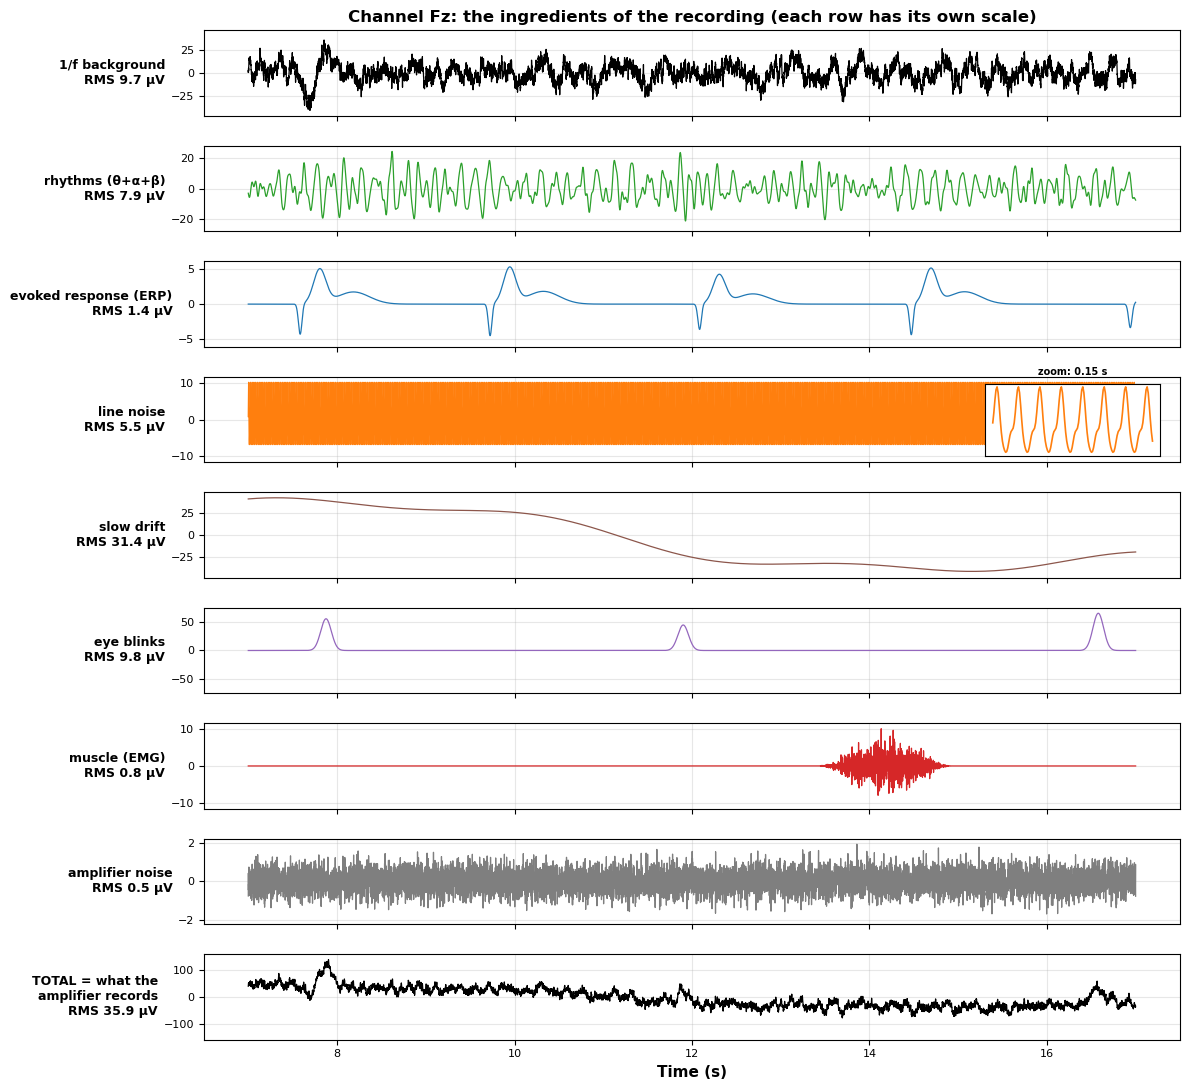

In [17]:
CH_SHOW = "Fz"
ci = CH_NAMES.index(CH_SHOW)
c = sim["comp"]
groups = [
    ("1/f background", c["1/f background"][ci], "k"),
    ("rhythms (θ+α+β)", (c["theta"] + c["alpha"] + c["beta"])[ci], "tab:green"),
    ("evoked response (ERP)", c["ERP"][ci], "tab:blue"),
    ("line noise", c["line noise"][ci], "tab:orange"),
    ("slow drift", c["slow drift"][ci], "tab:brown"),
    ("eye blinks", c["eye blinks"][ci], "tab:purple"),
    ("muscle (EMG)", c["muscle (EMG)"][ci], "tab:red"),
    ("amplifier noise", c["amplifier noise"][ci], "tab:gray"),
    ("TOTAL = what the\namplifier records", sim["eeg"][ci], "k"),
]
fig, axes = plt.subplots(len(groups), 1, figsize=(12, 11), sharex=True)
for ax, (label, x, col) in zip(axes, groups):
    ax.plot(sim["t"][sl], x[sl], color=col, lw=0.9)
    lim = 1.15 * np.max(np.abs(x[sl]))
    ax.set_ylim(-lim, lim)
    ax.set_ylabel(f"{label}\nRMS {rms(x[sl]):.1f} µV", rotation=0, ha="right", va="center", fontsize=9)
    ax.tick_params(labelsize=8)
ins = axes[3].inset_axes([0.80, 0.08, 0.18, 0.84])   # zoom into the line noise: 10 s of 50 Hz is just a solid band
ins.plot(sim["t"][sl][:150], groups[3][1][sl][:150], color="tab:orange", lw=1.2)
ins.set_title("zoom: 0.15 s", fontsize=7)
ins.set_xticks([])
ins.set_yticks([])
axes[0].set_title(f"Channel {CH_SHOW}: the ingredients of the recording (each row has its own scale)")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

### 6.3 Where does each ingredient live in the frequency domain?
This is the key picture for the rest of the notebook. **A filter can only separate things that occupy different
frequencies.** Look at what overlaps with what:
* **drift** and **blinks** sit at the very low end (below a few Hz) — a *high-pass* filter targets them;
* **line noise** is a set of narrow spikes (50, 100, 150 Hz) — a *notch* filter targets them;
* **muscle** is broad and high (30–250 Hz) — a *low-pass* filter targets it;
* but the **ERP**, **delta/theta** brain activity and **blinks** overlap in the low frequencies, and the **gamma-band** brain
  activity overlaps with muscle. No filter can separate those perfectly — that is where the trade-offs of section 8 come from.

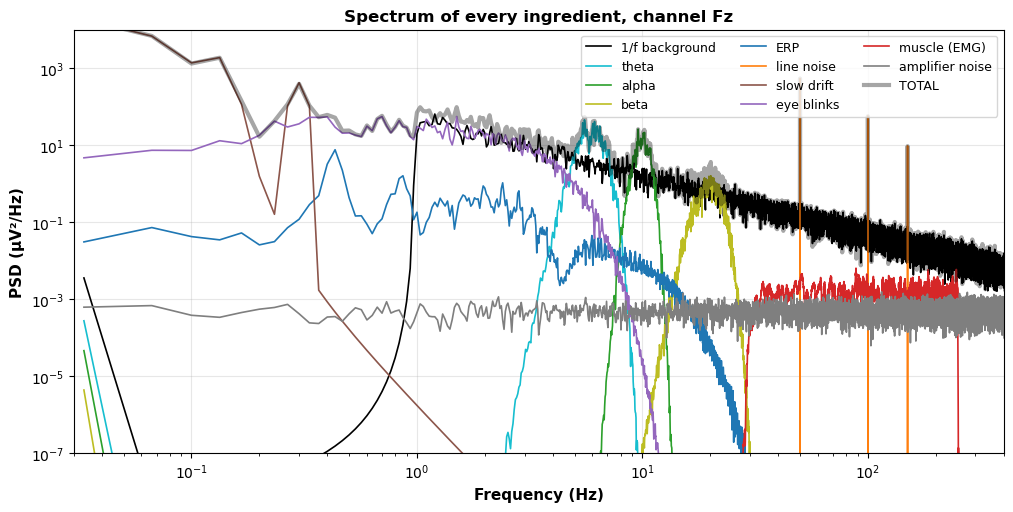

In [18]:
fig, ax = plt.subplots(figsize=(12, 5.5))
comp_colors = {"1/f background": "k", "theta": "tab:cyan", "alpha": "tab:green", "beta": "tab:olive", "ERP": "tab:blue",
               "line noise": "tab:orange", "slow drift": "tab:brown", "eye blinks": "tab:purple", "muscle (EMG)": "tab:red",
               "amplifier noise": "tab:gray"}
for name, col in comp_colors.items():
    f, p = welch_uV(sim["comp"][name][ci], seconds=30)
    ax.loglog(f[1:], p[1:], color=col, lw=1.2, label=name)
f, p = welch_uV(sim["eeg"][ci], seconds=30)
ax.loglog(f[1:], p[1:], color="k", lw=3, alpha=0.35, label="TOTAL")
ax.set_xlim(0.03, 400)
ax.set_ylim(1e-7, 1e4)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("PSD (µV²/Hz)")
ax.set_title(f"Spectrum of every ingredient, channel {CH_SHOW}")
ax.legend(ncol=3, loc="upper right")
plt.show()

### 6.4 The ERP is buried — until you average
Cut the continuous recording into **epochs** around each stimulus (`mne.Epochs`) and look at channel Pz.
A single trial shows nothing but noise. Averaging *N* trials reduces the noise roughly by **√N** while the
stimulus-locked ERP stays — so the ERP gradually emerges. The red dashed curve is the **ground-truth ERP**.

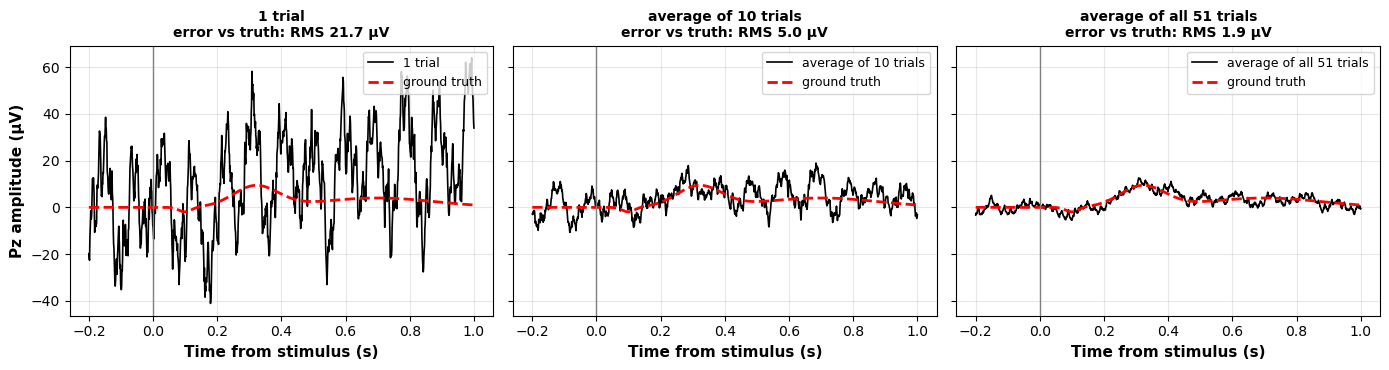

In [19]:
epochs = mne.Epochs(raw, events, event_id=1, tmin=-0.2, tmax=1.0, baseline=(None, 0), preload=True, verbose=False)
pz = CH_NAMES.index("Pz")
trials = epochs.get_data()[:, pz, :] * 1e6          # trials x time, µV
times = epochs.times
truth = erp_truth(times)[pz]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (n_avg, lab) in zip(axes, [(1, "1 trial"), (10, "average of 10 trials"), (len(trials), f"average of all {len(trials)} trials")]):
    avg = trials[:n_avg].mean(axis=0)
    ax.plot(times, avg, "k", lw=1.2, label=lab)
    ax.plot(times, truth, "r--", lw=2, label="ground truth")
    ax.axvline(0, color="gray", lw=1)
    ax.set_xlabel("Time from stimulus (s)")
    ax.set_title(f"{lab}\nerror vs truth: RMS {rms(avg - truth):.1f} µV", fontsize=10)
    ax.legend(loc="upper right")
axes[0].set_ylabel("Pz amplitude (µV)")
plt.tight_layout()
plt.show()

### 6.5 MNE's own spectrum view
The same information using MNE's built-in tools. `raw.compute_psd()` returns a `Spectrum` object whose `.plot()`
shows the PSD of every channel in dB. (Look for the alpha bump around 10 Hz, the mains lines at 50/100/150 Hz,
and the high-frequency "shelf" of channel T7 caused by muscle activity.)

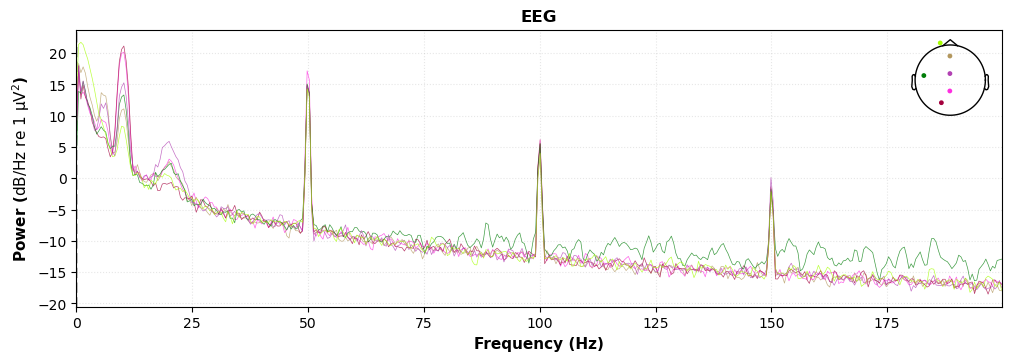

In [20]:
spectrum = raw.compute_psd(method="welch", fmax=200, n_fft=2048, verbose=False)
fig = spectrum.plot(average=False, picks="eeg", show=False)
plt.show()

---
# Part B — What MNE filters do

## 7. MNE filtering: the basics

A digital filter replaces every sample by a weighted combination of neighbouring samples. Its effect is described in
the frequency domain by its **frequency response**: for every frequency, how much the filter *scales* it (the
**magnitude** or *gain*) and how much it *delays* it (the **phase**). MNE offers two main entry points:

| Call | Effect |
|---|---|
| `raw.filter(l_freq=None, h_freq=40)` | **low-pass** — keep everything below 40 Hz |
| `raw.filter(l_freq=1, h_freq=None)` | **high-pass** — keep everything above 1 Hz |
| `raw.filter(l_freq=1, h_freq=40)` | **band-pass** — keep 1–40 Hz |
| `raw.filter(l_freq=52, h_freq=48)` | **band-stop** — if `l_freq > h_freq`, the band between them is removed |
| `raw.notch_filter(freqs=[50, 100, 150])` | narrow **notches** at the mains frequency and its harmonics |

and these are the main design settings (all have sensible defaults — section 8 explores what happens when you change them):

| Setting | Default | Meaning |
|---|---|---|
| `method` | `'fir'` | `'fir'` (finite impulse response) or `'iir'` (infinite impulse response, e.g. Butterworth) |
| `phase` | `'zero'` | `'zero'`: no time shift, but *non-causal*. Causal alternatives: `'minimum'` (FIR) or `'forward'` (IIR) |
| `l_trans_bandwidth`, `h_trans_bandwidth` | `'auto'` | width of the *transition band* between pass- and stop-band |
| `filter_length` | `'auto'` | length of the FIR filter (set by the transition bandwidth) |
| `fir_window`, `fir_design` | `'hamming'`, `'firwin'` | how the FIR filter is designed |
| `iir_params` | `None` | e.g. `dict(order=4, ftype='butter')` |
| `pad` | `'reflect_limited'` | how the signal edges are padded before filtering |

`raw.filter()` modifies the data **in place**, so below we always filter a `raw.copy()`.
And an important rule of thumb: **filter the continuous data, then epoch** — not the other way round (section 8.7).

### 7.1 Four basic filters, before and after
For each filter: left = a 10 s stretch of one channel (grey = before, blue = after); right = the PSD before and after
(log-log). The dashed lines mark the cutoff frequencies we asked for. Pay attention to *which part of the signal changed*.

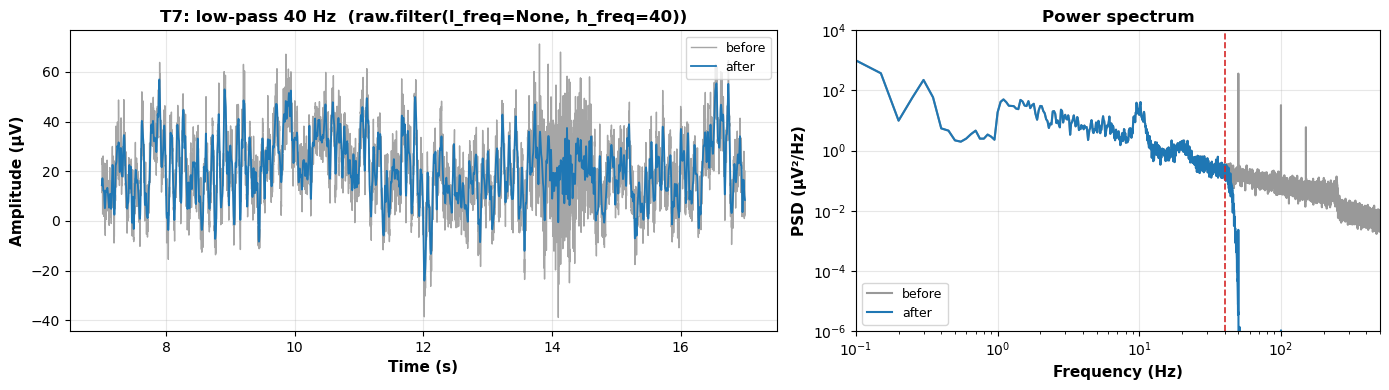

In [21]:
def apply(raw_in, **kw):
    """Band-pass / low-pass / high-pass a COPY of `raw_in` with MNE (the original stays untouched)."""
    return raw_in.copy().filter(verbose=False, **kw)


def compare_filter(raw_in, raw_out, ch, window=WIN, title="", marks=(), psd_seconds=20, ylim=None):
    """Before/after view of one channel: time domain (left) and power spectrum (right)."""
    ci = raw_in.ch_names.index(ch)
    x_in, x_out = raw_uV(raw_in)[ci], raw_uV(raw_out)[ci]
    t = np.arange(len(x_in)) / raw_in.info["sfreq"]
    sl = slice(int(window[0] * FS), int(window[1] * FS))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw=dict(width_ratios=[1.35, 1]))
    a1.plot(t[sl], x_in[sl], color="0.65", lw=1.0, label="before")
    a1.plot(t[sl], x_out[sl], color="tab:blue", lw=1.3, label="after")
    a1.set_xlabel("Time (s)")
    a1.set_ylabel("Amplitude (µV)")
    a1.set_title(f"{ch}: {title}")
    a1.legend(loc="upper right")
    if ylim:
        a1.set_ylim(*ylim)
    f, p_in = welch_uV(x_in, seconds=psd_seconds)
    _, p_out = welch_uV(x_out, seconds=psd_seconds)
    a2.loglog(f[1:], p_in[1:], color="0.6", lw=1.5, label="before")
    a2.loglog(f[1:], p_out[1:], color="tab:blue", lw=1.5, label="after")
    for m in marks:
        a2.axvline(m, color="tab:red", ls="--", lw=1.2)
    a2.set_xlim(0.1, 500)
    a2.set_ylim(1e-6, 1e4)
    a2.set_xlabel("Frequency (Hz)")
    a2.set_ylabel("PSD (µV²/Hz)")
    a2.set_title("Power spectrum")
    a2.legend(loc="lower left")
    plt.tight_layout()
    plt.show()


# --- low-pass 40 Hz -------------------------------------------------------------------------------------------
raw_lp = apply(raw, l_freq=None, h_freq=40)
compare_filter(raw, raw_lp, "T7", title="low-pass 40 Hz  (raw.filter(l_freq=None, h_freq=40))", marks=[40])

**Low-pass 40 Hz:** the burst of muscle noise on T7 (high-frequency "fuzz") is largely gone, as is everything else above
~45 Hz including the mains lines at 50/100/150 Hz. The slow waves, alpha rhythm and blinks are untouched.
The price: any real brain activity above 40 Hz (gamma) is gone too.

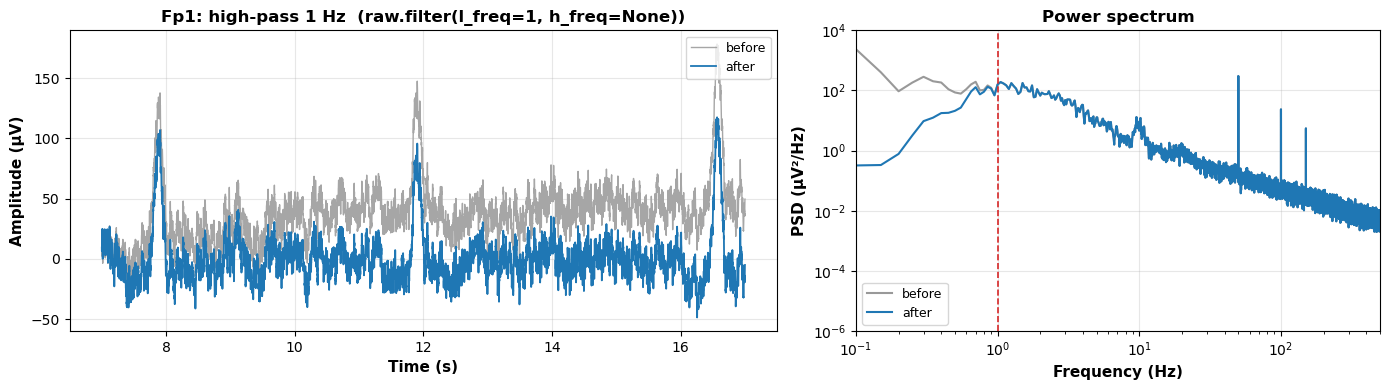

In [22]:
# --- high-pass 1 Hz -------------------------------------------------------------------------------------------
raw_hp = apply(raw, l_freq=1.0, h_freq=None)
compare_filter(raw, raw_hp, "Fp1", title="high-pass 1 Hz  (raw.filter(l_freq=1, h_freq=None))", marks=[1])

**High-pass 1 Hz:** the slow drift that made Fp1 wander (tens of µV!) is removed and the trace now oscillates
around zero — the left end of the spectrum drops by orders of magnitude. The **blinks are still there**,
only slightly reshaped: a blink is a brief event whose spectrum extends well above 1 Hz, so a high-pass cannot
remove it. (That is a job for ICA or regression-based artifact correction, not for filtering.)

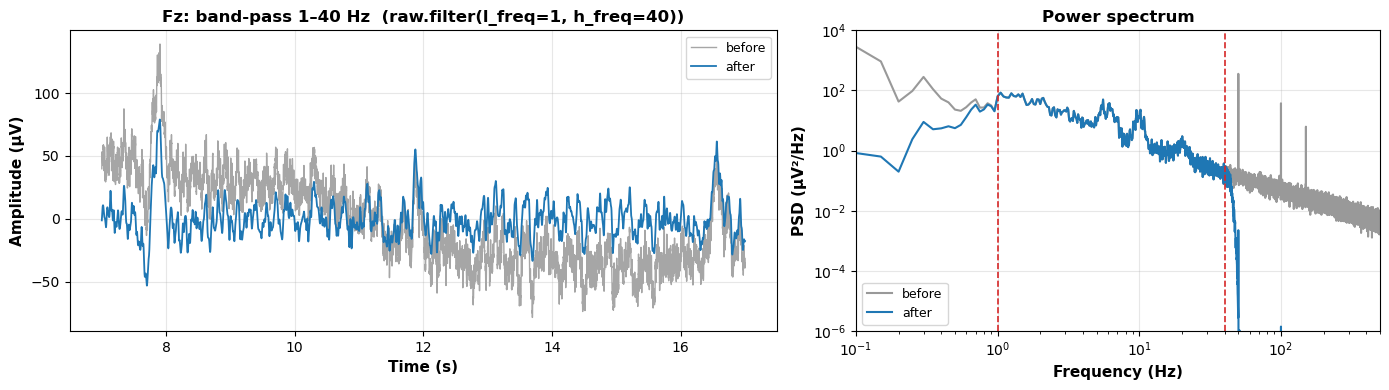

In [23]:
# --- band-pass 1-40 Hz ----------------------------------------------------------------------------------------
raw_bp = apply(raw, l_freq=1.0, h_freq=40.0)
compare_filter(raw, raw_bp, "Fz", title="band-pass 1–40 Hz  (raw.filter(l_freq=1, h_freq=40))", marks=[1, 40])

**Band-pass 1–40 Hz** = both of the above at once: the classic "clean-up" for ongoing EEG. What remains is mainly
the delta-to-beta activity.

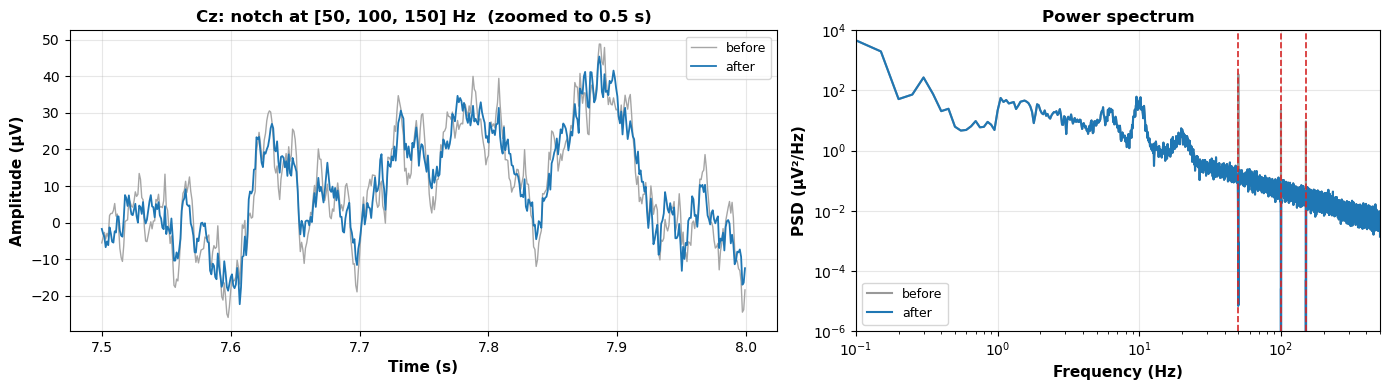

In [24]:
# --- notch at the mains frequency and its harmonics ------------------------------------------------------------
mains = [LINE_FREQ * k for k in (1, 2, 3)]
raw_notch = raw.copy().notch_filter(freqs=mains, verbose=False)
zoom = (WIN[0] + 0.5, WIN[0] + 1.0)  # zoom in so that the individual 50 Hz cycles are visible
compare_filter(raw, raw_notch, "Cz", window=zoom, title=f"notch at {mains} Hz  (zoomed to 0.5 s)", marks=mains)

**Notch filter:** a *very* narrow cut at 50 Hz (and the harmonics) removes the mains interference but leaves the neighbouring
frequencies — and all the slow activity — alone. In the spectrum you see three thin "bites" instead of
spikes. In the left plot the regular 50 Hz ripple on top of the EEG disappears.

### 7.2 A ground-truth scorecard
Here is the payoff of simulating the recording as separate ingredients. **Filtering is a linear operation**:
filtering the sum equals the sum of the filtered parts. (We verify that right now.) So we can filter each ingredient
on its own and measure exactly how much of it **survives** each filter — something impossible with real data.

In [25]:
raw_brain = make_raw(sim["brain"], CH_NAMES)
raw_artifacts = make_raw(sim["artifacts"], CH_NAMES)
test = dict(l_freq=1.0, h_freq=40.0)
filtered_total = apply(raw, **test).get_data()
filtered_parts = apply(raw_brain, **test).get_data() + apply(raw_artifacts, **test).get_data()
print(f"max |filter(brain + artifacts) - (filter(brain) + filter(artifacts))| = "
      f"{np.max(np.abs(filtered_total - filtered_parts)) * 1e6:.2e} µV   -> linear (differences are just rounding errors)")

max |filter(brain + artifacts) - (filter(brain) + filter(artifacts))| = 5.42e-14 µV   -> linear (differences are just rounding errors)


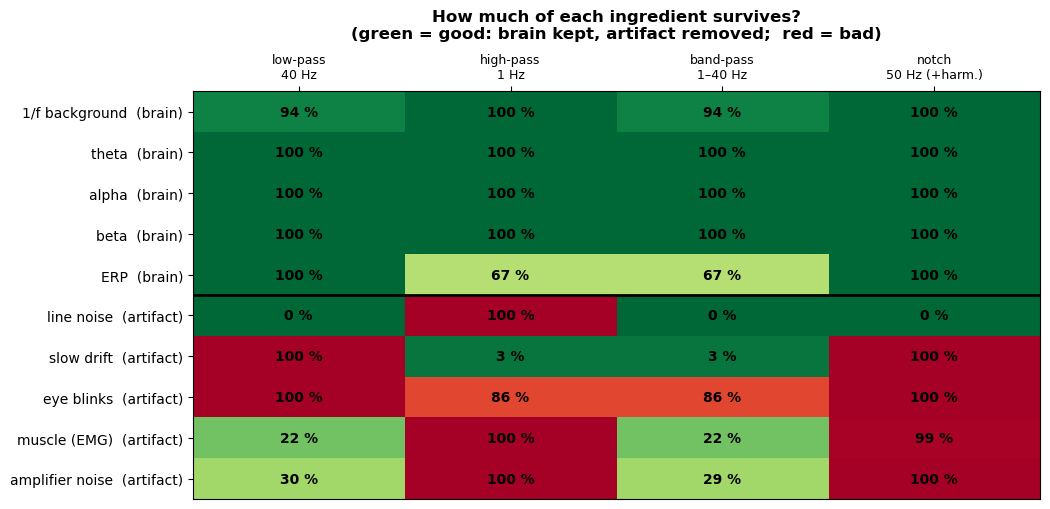

In [26]:
def survival_table(filter_fns, trim=5.0):
    """% of each ingredient's RMS that survives each filter (first/last `trim` seconds are excluded: edge effects)."""
    names = list(sim["comp"])
    out = np.zeros((len(names), len(filter_fns)))
    sl = slice(int(trim * FS), -int(trim * FS))
    for i, name in enumerate(names):
        r_comp = make_raw(sim["comp"][name], CH_NAMES)
        before = r_comp.get_data()[:, sl]
        for j, fn in enumerate(filter_fns.values()):
            after = fn(r_comp).get_data()[:, sl]
            out[i, j] = 100 * np.sqrt(np.mean(after ** 2) / np.mean(before ** 2))
    return names, out


def plot_scorecard(filter_fns, title="How much of each ingredient survives?", trim=5.0):
    names, M = survival_table(filter_fns, trim)
    brain = ["1/f background", "theta", "alpha", "beta", "ERP"]
    good = np.array([[(v / 100) if n in brain else 1 - v / 100 for v in row] for n, row in zip(names, M)])
    fig, ax = plt.subplots(figsize=(1.9 * len(filter_fns) + 3, 5.2))
    ax.imshow(np.clip(good, 0, 1), cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.0f} %", ha="center", va="center", fontsize=10, fontweight="bold")
    ax.set_xticks(range(len(filter_fns)))
    ax.set_xticklabels(list(filter_fns), fontsize=9)
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels([f"{n}  {'(brain)' if n in brain else '(artifact)'}" for n in names])
    ax.axhline(len(brain) - 0.5, color="k", lw=2)
    ax.grid(False)
    ax.xaxis.tick_top()
    ax.set_title(title + "\n(green = good: brain kept, artifact removed;  red = bad)", pad=38)
    plt.tight_layout()
    plt.show()
    return names, M


filters = {
    "low-pass\n40 Hz": lambda r: apply(r, l_freq=None, h_freq=40),
    "high-pass\n1 Hz": lambda r: apply(r, l_freq=1, h_freq=None),
    "band-pass\n1–40 Hz": lambda r: apply(r, l_freq=1, h_freq=40),
    f"notch\n{LINE_FREQ} Hz (+harm.)": lambda r: r.copy().notch_filter(freqs=mains, verbose=False),
}
_ = plot_scorecard(filters)

Reading the scorecard (percentages are the *RMS amplitude* that remains, pooled over all channels):
* **Slow drift** is wiped out by anything with a high-pass; **line noise** by the notch (and the low-pass);
  **EMG** is attenuated only by the low-pass.
* The **ERP** row shows the cost of filtering: a 1 Hz high-pass removes about **a third** of the ERP's RMS (the P3 and the
  slow wave are *slow* events), whereas a 40 Hz low-pass leaves it intact. A cutoff that is fine for ongoing EEG
  can be harmful for ERPs — section 8.1 digs into this.
* Our simulated **1/f background** was generated from 1 Hz upwards, so the 1 Hz high-pass leaves it alone; in real EEG,
  brain activity below 1 Hz would be removed too. The low-pass removes the few percent that lie above ~45 Hz.
* **Eye blinks** stay mostly intact under every filter (86 % after a high-pass) — a reminder that filters separate
  things by *frequency*, and blinks share their frequencies with brain slow waves.

### 7.3 Under the hood: reading MNE's filter log
MNE can tell you exactly what filter it built. Run the next cell and read the message.

In [27]:
with mne.use_log_level("INFO"):
    _ = raw.copy().filter(l_freq=1.0, h_freq=40.0)

Filtering raw data in 1 contiguous segment


Setting up band-pass filter from 1 - 40 Hz


FIR filter parameters


---------------------


Designing a one-pass, zero-phase, non-causal bandpass filter:


- Windowed time-domain design (firwin) method


... (2 outputs left out)

- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)


- Upper passband edge: 40.00 Hz


- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)


- Filter length: 3301 samples (3.301 s)


Three details in that log trip people up:
* **"Lower passband edge: 1.00 Hz … (−6 dB cutoff frequency: 0.50 Hz)".** In MNE, `l_freq=1` means the *passband* starts
  at 1 Hz. The filter's gain is already down to **half (−6 dB) at 0.5 Hz**, half-way through the transition band.
  Likewise `h_freq=40` ends the passband at 40 Hz and the −6 dB point is at 45 Hz.
* **The transition bandwidth is chosen automatically** (here 1 Hz at the low end and 10 Hz at the high end) —
  narrower for lower cutoffs. It determines the **filter length** (3301 samples = 3.3 s!).
* **"zero-phase, non-causal":** the filter looks both backwards *and forwards* in time (section 8.5).

We can *measure* any MNE filter by sending a single unit impulse through the exact same function and looking at
what comes out — the **impulse response** — and its Fourier transform, the **frequency response**. The helper below
does that, and `mne.viz.plot_filter` draws the standard picture.

In [28]:
def measure_filter(fs=FS, seconds=40, **kw):
    """Empirical response of an MNE filter: pass a unit impulse through mne.filter.filter_data with the same settings.
    Returns (freqs, complex frequency response H, times of the impulse response, impulse response)."""
    n = int(seconds * fs)
    x = np.zeros((1, n))
    x[0, n // 2] = 1.0
    y = mne.filter.filter_data(x, fs, verbose=False, **kw)[0]
    H = np.fft.rfft(np.roll(y, -(n // 2)))            # shift so that the impulse sits at t = 0
    return np.fft.rfftfreq(n, 1 / fs), H, (np.arange(n) - n // 2) / fs, y


def gain_db(f, H, f0):
    """Gain (dB) of a filter at frequency f0."""
    return 20 * np.log10(np.interp(f0, f, np.abs(H)) + 1e-12)


f, H, _, _ = measure_filter(l_freq=1.0, h_freq=40.0)
for f0, what in [(0.5, "-6 dB point of the high-pass"), (1.0, "passband edge  l_freq"), (40.0, "passband edge  h_freq"),
                 (45.0, "-6 dB point of the low-pass"), (50.0, "mains frequency")]:
    print(f"gain at {f0:5.1f} Hz = {gain_db(f, H, f0):7.1f} dB   ({what})")

gain at   0.5 Hz =    -6.1 dB   (-6 dB point of the high-pass)
gain at   1.0 Hz =    -0.0 dB   (passband edge  l_freq)
gain at  40.0 Hz =    -0.0 dB   (passband edge  h_freq)
gain at  45.0 Hz =    -6.0 dB   (-6 dB point of the low-pass)
gain at  50.0 Hz =   -52.0 dB   (mains frequency)


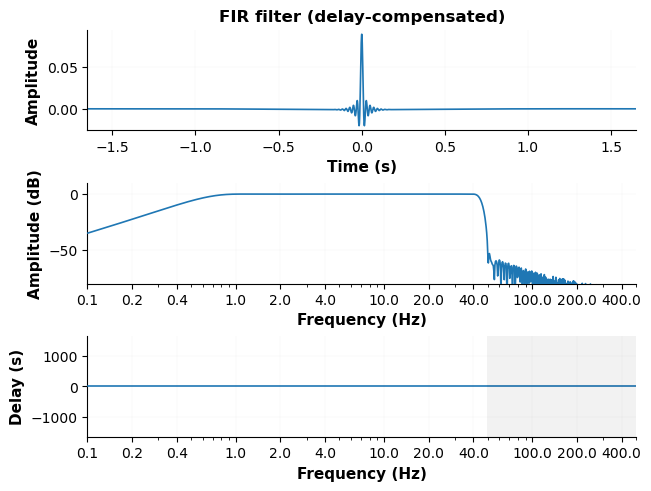

In [29]:
h = mne.filter.create_filter(None, FS, l_freq=1.0, h_freq=40.0, verbose=False)   # the FIR filter coefficients
fig = mne.viz.plot_filter(h, FS, flim=(0.1, 500), fscale="log", compensate=True, show=False)
plt.show()

`plot_filter` shows (top to bottom) the **impulse response** (what the filter does to a single spike — note it is
symmetric around t = 0: it responds *before* the spike as well as after), the **magnitude response** in dB
(the pass-band, the two transition bands and the stop-band), and the **group delay** (here zero, because the delay of
the symmetric FIR filter is compensated for).

## 8. Filter settings: what changes, and why it matters

Now we change **one setting at a time** and measure the consequences against the ground truth. To judge distortion of
the evoked response we use a **noise-free copy of the ERP** (identical trials, no background) — a luxury only a
simulation offers: any difference between the filtered and the unfiltered average is *purely* caused by the filter.

Helper definitions first.

In [30]:
import warnings

# Noise-free continuous ERP recording: the exact ERP template at every stimulus onset, nothing else.
erp_clean = np.zeros_like(sim["eeg"])
for o in events[:, 0]:
    erp_clean[:, o + int(-0.5 * FS): o + int(1.5 * FS)] += erp_truth(sim["tau"])
raw_erp = make_raw(erp_clean, CH_NAMES)

# Use only stimuli away from the recording edges, so that we study the filter and not edge effects (see 8.7).
ev_mid = events[(events[:, 0] > 20 * FS) & (events[:, 0] < 100 * FS)]
interior = slice(int(20 * FS), int(100 * FS))
print(f"{len(ev_mid)} stimuli used for the ERP comparisons")


def erp_average(raw_in, ch):
    """Average ERP (µV) of channel `ch`: epochs from -0.2 to 1.0 s around each stimulus, baseline -0.2...0 s."""
    ep = mne.Epochs(raw_in, ev_mid, 1, tmin=-0.2, tmax=1.0, baseline=(None, 0), preload=True, verbose=False)
    return ep.times, ep.get_data(picks=ch)[:, 0, :].mean(axis=0) * 1e6


def remaining_pct(raw_comp, filt_fn):
    """% of a component's RMS that is still there after filtering (interior of the recording only)."""
    out = filt_fn(raw_comp).get_data()[:, interior]
    return 100 * np.sqrt(np.mean(out ** 2) / np.mean(raw_comp.get_data()[:, interior] ** 2))


drift_raw = make_raw(sim["comp"]["slow drift"], CH_NAMES)
emg_raw = make_raw(sim["comp"]["muscle (EMG)"], CH_NAMES)

35 stimuli used for the ERP comparisons


### 8.1 The high-pass cutoff: drift removal versus ERP distortion
A high-pass filter removes slow drift — good — but ERP components are *slow* too. The left plot shows the
noise-free ERP at **Pz** after high-pass filters with different cutoffs (thick grey = the truth). The right plot
shows the trade-off over a range of cutoffs: how much **drift remains** (want: low) and how much the **ERP is
distorted** (want: low).

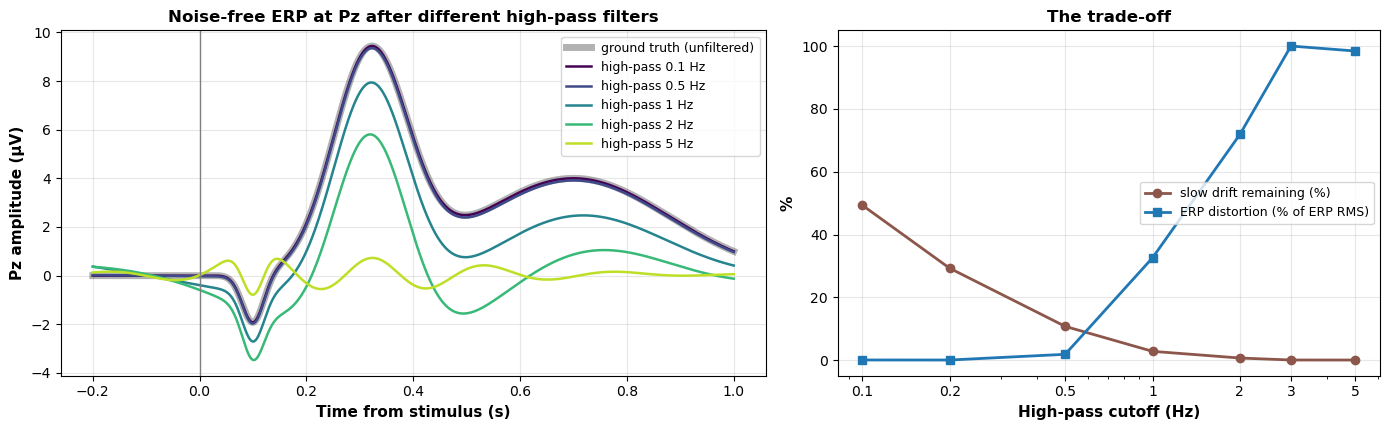

cutoff (Hz) | drift remaining | ERP distortion
     0.1    |      49.3 %     |      0.0 %
     0.2    |      29.2 %     |      0.0 %
     0.5    |      10.7 %     |      1.8 %
     1.0    |       2.8 %     |     32.6 %
     2.0    |       0.6 %     |     71.9 %
     3.0    |       0.0 %     |    100.0 %
     5.0    |       0.0 %     |     98.5 %


In [31]:
sweep = [0.1, 0.2, 0.5, 1.0, 2.0, 3.0, 5.0]
avgs, drift_left, erp_err = {}, [], []
times, truth = erp_average(raw_erp, "Pz")
for fc in sweep:
    fn = lambda r, fc=fc: apply(r, l_freq=fc, h_freq=None)
    drift_left.append(remaining_pct(drift_raw, fn))
    _, avgs[fc] = erp_average(fn(raw_erp), "Pz")
    erp_err.append(100 * rms(avgs[fc] - truth) / rms(truth))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw=dict(width_ratios=[1.3, 1]))
a1.plot(times, truth, "k", lw=5, alpha=0.3, label="ground truth (unfiltered)")
for fc, col in zip([0.1, 0.5, 1.0, 2.0, 5.0], plt.cm.viridis(np.linspace(0, 0.9, 5))):
    a1.plot(times, avgs[fc], color=col, lw=1.8, label=f"high-pass {fc:g} Hz")
a1.axvline(0, color="gray", lw=1)
a1.set_xlabel("Time from stimulus (s)")
a1.set_ylabel("Pz amplitude (µV)")
a1.set_title("Noise-free ERP at Pz after different high-pass filters")
a1.legend(loc="upper right")
a2.semilogx(sweep, drift_left, "o-", color="tab:brown", lw=2, label="slow drift remaining (%)")
a2.semilogx(sweep, erp_err, "s-", color="tab:blue", lw=2, label="ERP distortion (% of ERP RMS)")
a2.set_xlabel("High-pass cutoff (Hz)")
a2.set_ylabel("%")
a2.set_title("The trade-off")
a2.legend(loc="center right")
a2.set_xticks(sweep)
a2.set_xticklabels([f"{s:g}" for s in sweep])
plt.tight_layout()
plt.show()
print("cutoff (Hz) | drift remaining | ERP distortion")
for fc, d, e in zip(sweep, drift_left, erp_err):
    print(f"   {fc:5.1f}    |     {d:5.1f} %     |    {e:5.1f} %")

**Reading the result.**
* **0.1–0.5 Hz:** the ERP is essentially untouched (distortion ≤ 2 %), but *drift is only partly removed* — the simulated
  drift contains 0.12 and 0.3 Hz components that lie inside the pass-band of a 0.1 Hz filter.
* **1 Hz:** drift is almost gone (≈ 3 % left) but the ERP is already **visibly distorted**: the P3 loses roughly 15 %, the slow
  wave about 40 %, and a spurious **negative drift appears before the stimulus (t < 0)**. This is the zero-phase filter
  "leaking" the distortion backwards in time.
* **2 Hz and above:** most of the ERP is destroyed.

There is no universally right cutoff: it depends on how slow the signal of interest is. ERP researchers interested in slow
components often stay at or below ~0.1 Hz, while analyses that are sensitive to drift (for instance ICA) benefit from
~1 Hz. The point is to **choose deliberately** and know what you pay.

### 8.2 The low-pass cutoff: muscle removal versus sharp features
The mirror image. A low-pass filter removes high-frequency muscle noise — but it also **smooths sharp features**, such
as the narrow N1 peak (20 ms wide) of our ERP. We look at channel **Cz**, where the N1 is large.

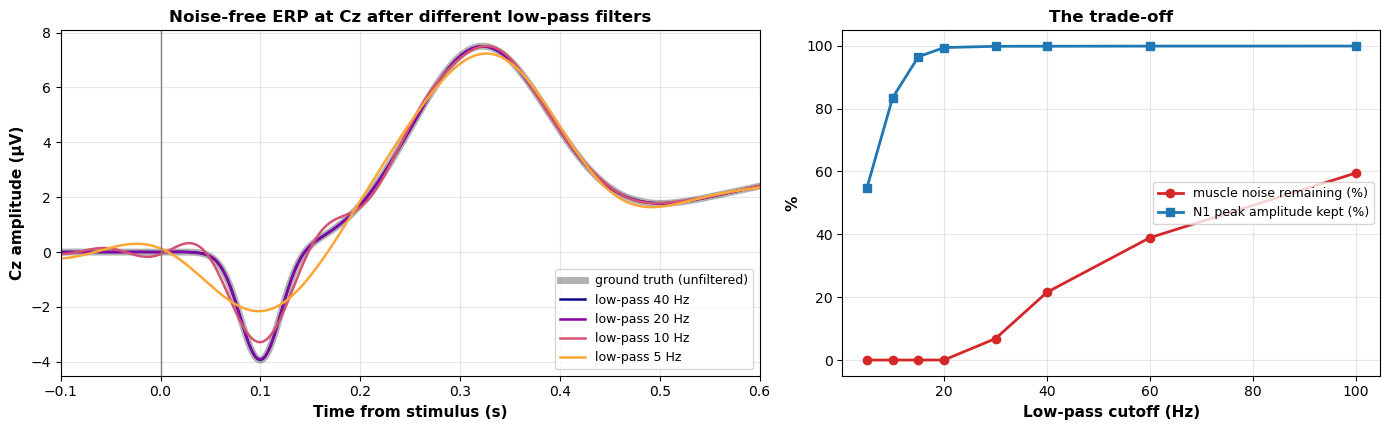

cutoff (Hz) | muscle remaining | N1 peak kept
       5    |        0.0 %    |     54.8 %
      10    |        0.0 %    |     83.4 %
      15    |        0.0 %    |     96.5 %
      20    |        0.0 %    |     99.4 %
      30    |        6.8 %    |     99.8 %
      40    |       21.6 %    |     99.8 %
      60    |       38.9 %    |     99.9 %
     100    |       59.5 %    |     99.9 %


In [32]:
sweep = [5, 10, 15, 20, 30, 40, 60, 100]
times, truth_cz = erp_average(raw_erp, "Cz")
win_n1 = (times >= 0.06) & (times <= 0.14)
avgs, emg_left, n1_kept = {}, [], []
for fc in sweep:
    fn = lambda r, fc=fc: apply(r, l_freq=None, h_freq=fc)
    emg_left.append(remaining_pct(emg_raw, fn))
    _, avgs[fc] = erp_average(fn(raw_erp), "Cz")
    n1_kept.append(100 * np.min(avgs[fc][win_n1]) / np.min(truth_cz[win_n1]))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw=dict(width_ratios=[1.3, 1]))
a1.plot(times, truth_cz, "k", lw=5, alpha=0.3, label="ground truth (unfiltered)")
for fc, col in zip([40, 20, 10, 5], plt.cm.plasma(np.linspace(0, 0.8, 4))):
    a1.plot(times, avgs[fc], color=col, lw=1.8, label=f"low-pass {fc} Hz")
a1.axvline(0, color="gray", lw=1)
a1.set_xlim(-0.1, 0.6)
a1.set_xlabel("Time from stimulus (s)")
a1.set_ylabel("Cz amplitude (µV)")
a1.set_title("Noise-free ERP at Cz after different low-pass filters")
a1.legend(loc="lower right")
a2.plot(sweep, emg_left, "o-", color="tab:red", lw=2, label="muscle noise remaining (%)")
a2.plot(sweep, n1_kept, "s-", color="tab:blue", lw=2, label="N1 peak amplitude kept (%)")
a2.set_xlabel("Low-pass cutoff (Hz)")
a2.set_ylabel("%")
a2.set_title("The trade-off")
a2.legend(loc="center right")
plt.tight_layout()
plt.show()
print("cutoff (Hz) | muscle remaining | N1 peak kept")
for fc, e, k in zip(sweep, emg_left, n1_kept):
    print(f"   {fc:5d}    |      {e:5.1f} %    |    {k:5.1f} %")

**Reading the result.** The ERP is robust against low-pass filtering down to ~20 Hz (the narrow N1 keeps 99 % of its
height); at 10 Hz it loses about 17 % and at 5 Hz about 45 %. The muscle noise (simulated between 30 and 250 Hz) is
completely removed by cutoffs ≤ 20 Hz, but a *typical* 40 Hz low-pass leaves ~20 % of it and 100 Hz leaves ~60 %.
So for ERPs a cutoff of 20–40 Hz is cheap; for **gamma-band** work you must keep the high frequencies — and
then the muscle noise is a problem that filtering cannot solve.

### 8.3 The transition bandwidth (and filter length)
A real filter cannot jump from "pass" to "stop": there is a **transition band** in which the gain falls gradually. MNE
chooses its width automatically (`'auto'`: 10 Hz for a 40 Hz low-pass), but you can set it with
`h_trans_bandwidth` / `l_trans_bandwidth`. A **narrower** transition = a **sharper** filter, but also a **longer** one.
The three panels show, for a 40 Hz low-pass: the magnitude response, the impulse response, and the **ringing** the filter
adds around an abrupt step (the *difference* between the filtered step and the ideal step, i.e. the unwanted wiggles).

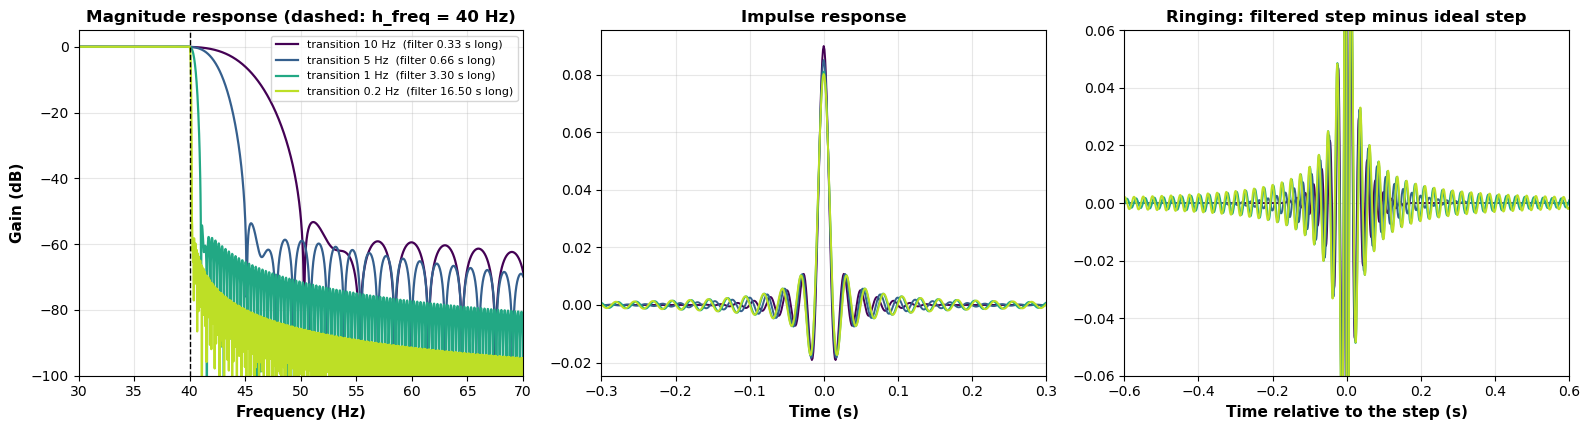

In [33]:
tbs = ["auto", 5, 1, 0.2]
cols = plt.cm.viridis(np.linspace(0, 0.9, len(tbs)))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for tb, col in zip(tbs, cols):
    f, H, t_ir, y = measure_filter(l_freq=None, h_freq=40, h_trans_bandwidth=tb)
    n_taps = len(mne.filter.create_filter(None, FS, None, 40, h_trans_bandwidth=tb, verbose=False))
    label = f"transition {10 if tb == 'auto' else tb:g} Hz  (filter {n_taps / FS:.2f} s long)"
    axes[0].plot(f, 20 * np.log10(np.abs(H) + 1e-12), color=col, lw=1.6, label=label)
    axes[1].plot(t_ir, y, color=col, lw=1.4, label=label)
    step_err = np.cumsum(y) - (t_ir >= 0)
    axes[2].plot(t_ir, step_err, color=col, lw=1.4, label=label)
axes[0].set_xlim(30, 70)
axes[0].set_ylim(-100, 5)
axes[0].axvline(40, color="k", ls="--", lw=1)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Gain (dB)")
axes[0].set_title("Magnitude response (dashed: h_freq = 40 Hz)")
axes[0].legend(loc="upper right", fontsize=8)
axes[1].set_xlim(-0.3, 0.3)
axes[1].set_xlabel("Time (s)")
axes[1].set_title("Impulse response")
axes[2].set_xlim(-0.6, 0.6)
axes[2].set_ylim(-0.06, 0.06)
axes[2].set_xlabel("Time relative to the step (s)")
axes[2].set_title("Ringing: filtered step minus ideal step")
plt.tight_layout()
plt.show()

**Reading the result.** Narrowing the transition from 10 Hz to 0.2 Hz makes the roll-off dramatically steeper (left) —
but the filter grows from 0.33 s to **16.5 s** long. The ringing (right) has a similar *height* in all cases (that is set by the
window, next section) but **lasts much longer** for the sharp filters, and note that it appears on **both sides** of the
step — before it as well as after it, because this is a zero-phase filter. A very sharp filter smears an abrupt event
(a blink onset, a spike, a stimulus artifact) over a long time. MNE's `'auto'` setting is a sensible compromise;
sharper is not automatically better.

### 8.4 The window function
MNE designs its FIR filters with the *window method*. The window (`fir_window`) trades **stop-band attenuation**
(how well unwanted frequencies are suppressed) against **filter length** (at the same transition bandwidth).

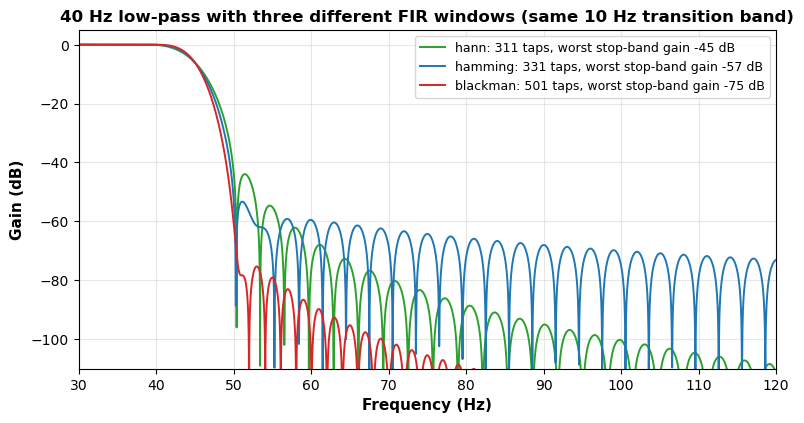

In [34]:
fig, ax = plt.subplots(figsize=(9, 4.4))
for win, col in zip(["hann", "hamming", "blackman"], ["tab:green", "tab:blue", "tab:red"]):
    f, H, _, _ = measure_filter(l_freq=None, h_freq=40, fir_window=win)
    n_taps = len(mne.filter.create_filter(None, FS, None, 40, fir_window=win, verbose=False))
    atten = 20 * np.log10(np.abs(H[f >= 52]).max())
    ax.plot(f, 20 * np.log10(np.abs(H) + 1e-12), color=col, lw=1.4,
            label=f"{win}: {n_taps} taps, worst stop-band gain {atten:.0f} dB")
ax.set_xlim(30, 120)
ax.set_ylim(-110, 5)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Gain (dB)")
ax.set_title("40 Hz low-pass with three different FIR windows (same 10 Hz transition band)")
ax.legend(loc="upper right")
plt.show()

The default (`hamming`) suppresses the stop-band by roughly 55 dB; `blackman` buys ~20 dB more at the price of a ~50 % longer
filter; `hann` is shorter but suppresses less. For most EEG work the default is fine.

### 8.5 FIR vs IIR, zero-phase vs causal
This is the most consequential choice. Four variants of the same 1–40 Hz band-pass:

* **FIR, zero-phase** (the MNE default): symmetric impulse response, **no time shift** — but *non-causal*: the output
  at time *t* depends on the input at later times.
* **FIR, minimum-phase**: causal (the output depends only on the past) — with a delay that depends on frequency.
* **IIR Butterworth, zero-phase** (`phase='zero'`): the filter is run **forward and then backward**, which cancels the phase shift
  but squares the magnitude response (so a "−3 dB" Butterworth becomes −6 dB at its cutoff).
* **IIR Butterworth, causal** (`phase='forward'`): runs once, forward; a classic, but it **delays different frequencies by different amounts**.

Left: magnitude response. Middle: impulse response. Right: **group delay** — how many milliseconds each frequency is delayed.

filter                            gain at 1 Hz  gain at 40 Hz  gain at 50 Hz
FIR zero-phase (default)               -0.0 dB        -0.0 dB       -52.0 dB


FIR minimum-phase (causal)             -0.0 dB        -0.0 dB       -52.0 dB
IIR Butterworth 4, zero-phase          -6.0 dB        -6.0 dB       -17.6 dB
IIR Butterworth 4, causal              -3.0 dB        -3.0 dB        -8.8 dB


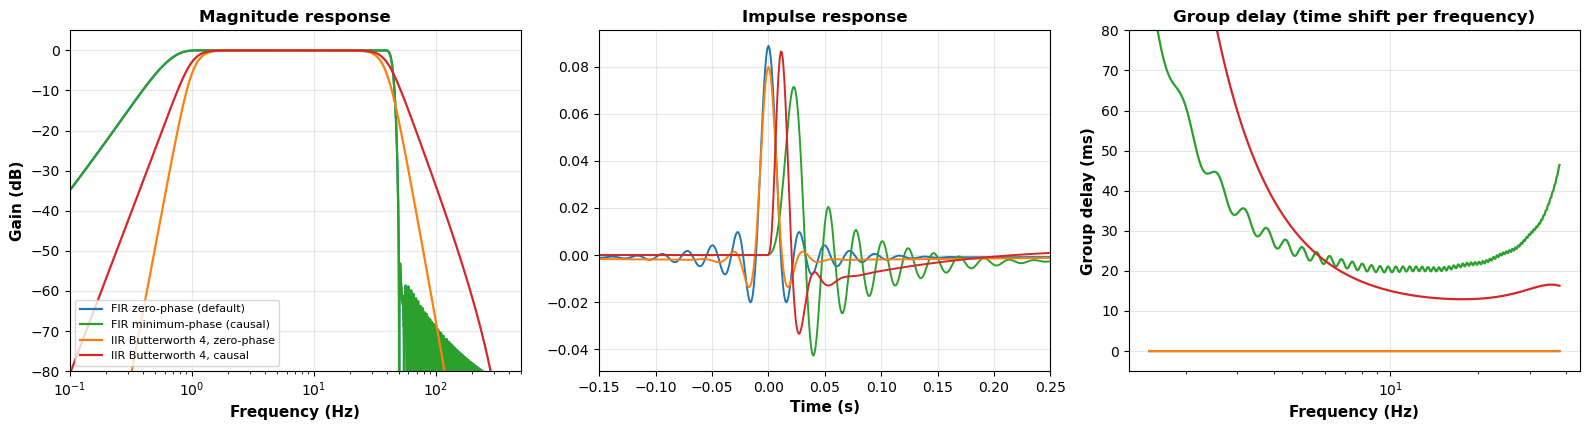

In [35]:
CONFIGS = {
    "FIR zero-phase (default)": dict(method="fir", phase="zero"),
    "FIR minimum-phase (causal)": dict(method="fir", phase="minimum"),
    "IIR Butterworth 4, zero-phase": dict(method="iir", phase="zero", iir_params=dict(order=4, ftype="butter")),
    "IIR Butterworth 4, causal": dict(method="iir", phase="forward", iir_params=dict(order=4, ftype="butter")),
}
cfg_cols = ["tab:blue", "tab:green", "tab:orange", "tab:red"]


def group_delay_ms(f, H):
    return -np.gradient(np.unwrap(np.angle(H)), 2 * np.pi * f) * 1000


fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
print(f"{'filter':32s} {'gain at 1 Hz':>13s} {'gain at 40 Hz':>14s} {'gain at 50 Hz':>14s}")
for (name, cfg), col in zip(CONFIGS.items(), cfg_cols):
    f, H, t_ir, y = measure_filter(l_freq=1.0, h_freq=40.0, **cfg)
    axes[0].semilogx(f[1:], 20 * np.log10(np.abs(H[1:]) + 1e-12), color=col, lw=1.6, label=name)
    axes[1].plot(t_ir, y, color=col, lw=1.4, label=name)
    gd = group_delay_ms(f, H)
    ok = (f >= 1.5) & (f <= 38)
    axes[2].semilogx(f[ok], gd[ok], color=col, lw=1.6, label=name)
    print(f"{name:32s} {gain_db(f, H, 1.0):10.1f} dB {gain_db(f, H, 40.0):11.1f} dB {gain_db(f, H, 50.0):11.1f} dB")
axes[0].set_xlim(0.1, 500)
axes[0].set_ylim(-80, 5)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Gain (dB)")
axes[0].set_title("Magnitude response")
axes[0].legend(loc="lower left", fontsize=8)
axes[1].set_xlim(-0.15, 0.25)
axes[1].set_xlabel("Time (s)")
axes[1].set_title("Impulse response")
axes[2].set_xlabel("Frequency (Hz)")
axes[2].set_ylabel("Group delay (ms)")
axes[2].set_title("Group delay (time shift per frequency)")
axes[2].set_ylim(-5, 80)
plt.tight_layout()
plt.show()

**Reading the result.**
* **"Cutoff" does not mean the same thing for every filter.** At the nominal cutoff the FIR filter still passes the signal
  fully (0 dB — the cutoff is the *edge* of the pass-band), the zero-phase IIR is down by **6 dB** and the causal IIR by **3 dB**.
* **IIR filters roll off much more gently**: at 50 Hz the FIR is ~52 dB down, the zero-phase IIR only ~18 dB and the
  causal IIR ~9 dB. Higher orders sharpen them.
* **Group delay (right):** zero-phase filters delay nothing (flat lines at 0 ms; the blue and orange curves lie on top of each other).
  The causal filters delay the passband by roughly **15–25 ms, and by *different* amounts at different frequencies** — which also
  changes the *shape* of the waveform. The delay climbs steeply near the high-pass edge.

What does this mean for the waves? The next cell feeds the noise-free ERP through each of the four filters
(as 20 Hz low-passes, to isolate the timing effect) and measures **when the peaks occur**. Latency is often *the* outcome of an ERP study.

filter (20 Hz low-pass)           N1 latency  P3 latency  P3 amplitude
ground truth                          100 ms      323 ms        9.4 µV
FIR zero-phase (default)              100 ms      323 ms        9.4 µV
FIR minimum-phase (causal)            140 ms      360 ms        9.4 µV


IIR Butterworth 4, zero-phase         100 ms      323 ms        9.4 µV
IIR Butterworth 4, causal             122 ms      344 ms        9.4 µV


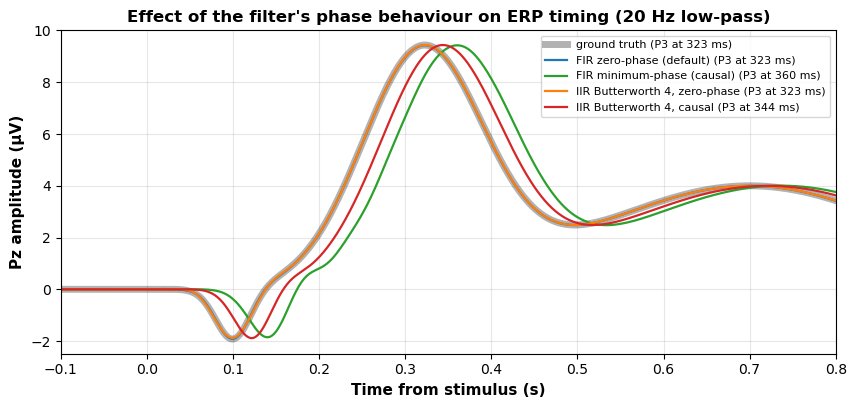

In [36]:
def peak_latency_ms(times, avg, window, kind):
    m = (times >= window[0]) & (times <= window[1])
    idx = np.argmax(avg[m]) if kind == "max" else np.argmin(avg[m])
    return 1000 * times[m][idx], avg[m][idx]


times, truth_pz = erp_average(raw_erp, "Pz")
_, truth_cz = erp_average(raw_erp, "Cz")
lat_p3_true, amp_p3_true = peak_latency_ms(times, truth_pz, (0.2, 0.45), "max")
lat_n1_true, amp_n1_true = peak_latency_ms(times, truth_cz, (0.05, 0.15), "min")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(times, truth_pz, "k", lw=5, alpha=0.3, label=f"ground truth (P3 at {lat_p3_true:.0f} ms)")
print(f"{'filter (20 Hz low-pass)':32s} {'N1 latency':>11s} {'P3 latency':>11s} {'P3 amplitude':>13s}")
print(f"{'ground truth':32s} {lat_n1_true:8.0f} ms {lat_p3_true:8.0f} ms {amp_p3_true:10.1f} µV")
for (name, cfg), col in zip(CONFIGS.items(), cfg_cols):
    r_f = apply(raw_erp, l_freq=None, h_freq=20, **cfg)
    _, a_pz = erp_average(r_f, "Pz")
    _, a_cz = erp_average(r_f, "Cz")
    l_p3, amp_p3 = peak_latency_ms(times, a_pz, (0.2, 0.45), "max")
    l_n1, _ = peak_latency_ms(times, a_cz, (0.05, 0.2), "min")
    ax.plot(times, a_pz, color=col, lw=1.6, label=f"{name} (P3 at {l_p3:.0f} ms)")
    print(f"{name:32s} {l_n1:8.0f} ms {l_p3:8.0f} ms {amp_p3:10.1f} µV")
ax.set_xlim(-0.1, 0.8)
ax.set_xlabel("Time from stimulus (s)")
ax.set_ylabel("Pz amplitude (µV)")
ax.set_title("Effect of the filter's phase behaviour on ERP timing (20 Hz low-pass)")
ax.legend(loc="upper right", fontsize=8)
plt.show()

**Reading the result.** The two zero-phase filters reproduce the true latencies exactly (N1 at 100 ms, P3 at 323 ms). Both causal
filters **shift the peaks later by roughly 20–40 ms** (the exact amount depends on the filter), without changing their height here.
That is the same size as the latency effects many ERP studies are looking for.

The trade-off: zero-phase filtering has no delay but is **non-causal** — it lets the effect of an event "leak" backwards in time (the
pre-ringing of section 8.3 and the negative drift before t = 0 in section 8.1). That can matter if you study **pre-stimulus**
activity or the **onset** of effects. Causal filtering never affects the past, but it delays and reshapes waves. The usual practice
is zero-phase filtering for offline analysis, and causal filters when you genuinely need causality (real-time or
brain–computer-interface applications), accepting — and, if needed, correcting for — the delay.

### 8.6 Notch filters and a nearby signal of interest
The mains frequency (50 Hz here) is often only a few Hz away from signals we care about — for example a
**60 Hz frequency-tagged response** like the carrier in `sine_models.ipynb` (60 Hz carrier, 20 Hz modulator, therefore
spectral lines at 40, 60 and 80 Hz). We simulate one channel with: 1/f background + 10 µV mains + a 3 µV tagged response,
and compare notch settings. For each we measure the amplitude left at each spectral line.

variant                                  40 Hz       50 Hz       60 Hz       80 Hz      <- amplitude (µV) left at each spectral line
no notch                                  0.76       10.01        1.50        0.74
FIR, default width (0.25 Hz)              0.76        0.02        1.50        0.74
FIR, notch_widths = 5 Hz                  0.76        0.01        1.50        0.74
FIR, notch_widths = 24 Hz                 0.00        0.00        0.00        0.74
spectrum_fit (sinusoid removal)           0.76        0.23        1.50        0.74


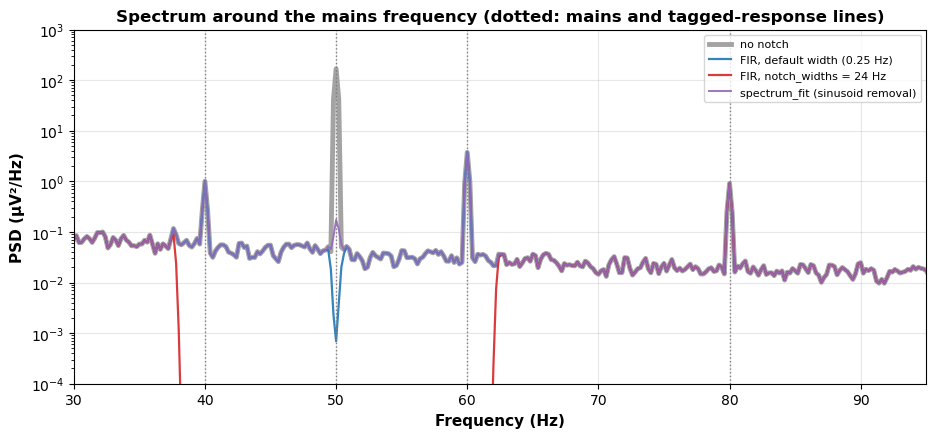

In [37]:
rr = np.random.default_rng(SEED + 1)
t60 = time_vec(60)
carrier_f, mod_f = LINE_FREQ + 10, 20
tag_lines = [carrier_f - mod_f, LINE_FREQ, carrier_f, carrier_f + mod_f]      # 40, 50, 60, 80 Hz for 50 Hz mains
x_tag = (pink_noise(len(t60), FS, 1.5, 5.0, rr)
         + 10 * np.sin(2 * np.pi * LINE_FREQ * t60 + 0.3)
         + am_signal(t60, carrier_f, mod_f, amp_uV=3)["am"])[None, :]


def line_amplitudes(sig, lines):
    X = 2 * np.abs(np.fft.rfft(sig)) / len(sig)
    f = np.fft.rfftfreq(len(sig), 1 / FS)
    return [X[np.argmin(np.abs(f - fl))] for fl in lines]


variants = {
    "no notch": None,
    "FIR, default width (0.25 Hz)": dict(),
    "FIR, notch_widths = 5 Hz": dict(notch_widths=5),
    "FIR, notch_widths = 24 Hz": dict(notch_widths=24),
    "spectrum_fit (sinusoid removal)": dict(method="spectrum_fit"),
}
shown = {"no notch": ("0.6", 3.5), "FIR, default width (0.25 Hz)": ("tab:blue", 1.6),
         "FIR, notch_widths = 24 Hz": ("tab:red", 1.6), "spectrum_fit (sinusoid removal)": ("tab:purple", 1.4)}
fig, ax = plt.subplots(figsize=(11, 4.6))
header = "".join(f"{fl:>9g} Hz" for fl in tag_lines)
print(f"{'variant':34s}{header}      <- amplitude (µV) left at each spectral line")
for name, kw in variants.items():
    y = x_tag if kw is None else mne.filter.notch_filter(x_tag, FS, freqs=LINE_FREQ, verbose=False, **kw)
    print(f"{name:34s}" + "".join(f"{a:12.2f}" for a in line_amplitudes(y[0], tag_lines)))
    if name in shown:
        col, lw = shown[name]
        fw, pw = welch_uV(y[0], seconds=5)
        ax.semilogy(fw, pw, color=col, lw=lw, alpha=0.9, label=name)
ax.set_xlim(LINE_FREQ - 20, LINE_FREQ + 45)
ax.set_ylim(1e-4, 1e3)
for fl in tag_lines:
    ax.axvline(fl, color="gray", ls=":", lw=1)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("PSD (µV²/Hz)")
ax.set_title("Spectrum around the mains frequency (dotted: mains and tagged-response lines)")
ax.legend(loc="upper right", fontsize=8)
plt.show()

**Reading the result.**
* A **narrow notch** (MNE's default width is only 0.25 Hz for 50 Hz) removes the mains line almost completely (10 → 0.02 µV)
  and leaves the tagged response — the lines at 40, 60 and 80 Hz — untouched. A 5 Hz stop-band behaves the same.
* A **24 Hz-wide notch** removes the mains but also **destroys the 40 and 60 Hz lines**, i.e. the carrier and one sideband of
  the signal of interest. Wide band-stop filters — or an over-eager low-pass — are a classic way to erase a response
  close to the mains frequency.
* `method='spectrum_fit'` removes the mains by *estimating and subtracting a sinusoid* (here down to 0.23 µV) instead of cutting
  a band; it also leaves the neighbouring lines alone, and does not touch the rest of the spectrum.

Keep notches **narrow**, and always check the spectrum around the notch afterwards.

### 8.7 Edge effects and padding
A filter needs samples on both sides of the one it is working on. At the **start and end** of a recording these
are missing, so MNE **pads** the signal (`pad='reflect_limited'` by default). The padding choice matters whenever
the signal does not start at zero — for example a recording with a DC offset. Test: a 10 Hz wave, 20 µV, sitting on a
**100 µV offset**, high-passed at 1 Hz (the right answer: the pure 10 Hz wave, offset gone).

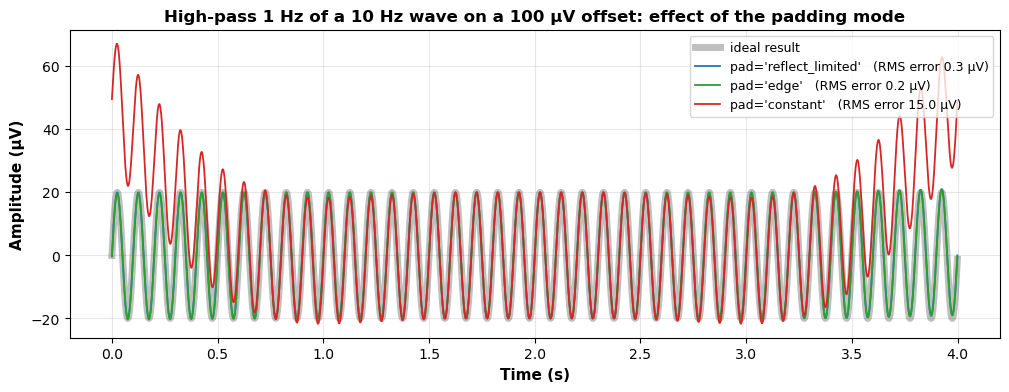

In [38]:
t4 = time_vec(4)
truth_wave = sine(t4, 10, 20)
seg = (100 + truth_wave)[None, :]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t4, truth_wave, "k", lw=5, alpha=0.25, label="ideal result")
for mode, col in zip(["reflect_limited", "edge", "constant"], ["tab:blue", "tab:green", "tab:red"]):
    y = mne.filter.filter_data(seg, FS, 1.0, None, pad=mode, verbose=False)[0]
    ax.plot(t4, y, color=col, lw=1.3, label=f"pad='{mode}'   (RMS error {rms(y - truth_wave):.1f} µV)")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude (µV)")
ax.set_title("High-pass 1 Hz of a 10 Hz wave on a 100 µV offset: effect of the padding mode")
ax.legend(loc="upper right")
plt.show()

`'constant'` pads with zeros: the filter "sees" a jump from 0 to 100 µV at both ends and produces a huge transient. The
default `'reflect_limited'` avoids it.

**Filter first, epoch afterwards.** A related trap is filtering *epochs* instead of the continuous recording. An epoch (here
1.2 s) is much shorter than a good filter (a 0.5 Hz high-pass wants a 6.6 s filter), so MNE warns that "distortion is likely".
Let's measure it with a 0.5 Hz high-pass, comparing **(a)** filtering the continuous data and then epoching with **(b)** epoching
first. We look at two things: how much the noise-free ERP at Pz is distorted, and how much slow drift is left inside the epochs.

MNE warns: filter_length (6601) is longer than the signal (1201), distortion is likely. Reduce filter length or filter a longer signal.


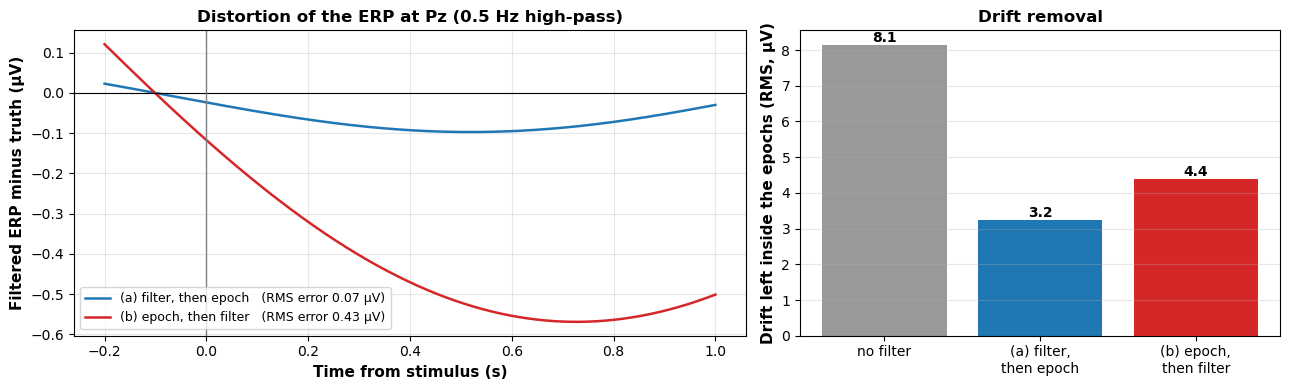

In [39]:
FC = 0.5
f_kw = dict(l_freq=FC, h_freq=None)


def epochs_of(raw_in, baseline):
    return mne.Epochs(raw_in, ev_mid, 1, tmin=-0.2, tmax=1.0, baseline=baseline, preload=True, verbose=False)


def epoch_then_filter(raw_in):
    ep = epochs_of(raw_in, None)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        ep.filter(verbose=False, **f_kw)
    return ep.apply_baseline((None, 0)), caught


times, truth_pz = erp_average(raw_erp, "Pz")
ep_a = epochs_of(apply(raw_erp, **f_kw), (None, 0))   # (a) filter the continuous data, then epoch
ep_b, caught = epoch_then_filter(raw_erp)             # (b) epoch first, then filter
if caught:
    print("MNE warns:", str(caught[0].message)[:200])
err_a = ep_a.get_data(picks="Pz")[:, 0].mean(axis=0) * 1e6 - truth_pz
err_b = ep_b.get_data(picks="Pz")[:, 0].mean(axis=0) * 1e6 - truth_pz

# drift left inside the epochs (all channels), baseline-corrected
d_none = epochs_of(drift_raw, (None, 0)).get_data()
d_a = epochs_of(apply(drift_raw, **f_kw), (None, 0)).get_data()
d_b = epoch_then_filter(drift_raw)[0].get_data()
d_rms = [rms(d.ravel()) * 1e6 for d in (d_none, d_a, d_b)]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw=dict(width_ratios=[1.4, 1]))
a1.plot(times, err_a, color="tab:blue", lw=1.8, label=f"(a) filter, then epoch   (RMS error {rms(err_a):.2f} µV)")
a1.plot(times, err_b, color="tab:red", lw=1.8, label=f"(b) epoch, then filter   (RMS error {rms(err_b):.2f} µV)")
a1.axhline(0, color="k", lw=0.8)
a1.axvline(0, color="gray", lw=1)
a1.set_xlabel("Time from stimulus (s)")
a1.set_ylabel("Filtered ERP minus truth (µV)")
a1.set_title(f"Distortion of the ERP at Pz ({FC} Hz high-pass)")
a1.legend(loc="lower left", fontsize=9)
a2.bar(["no filter", "(a) filter,\nthen epoch", "(b) epoch,\nthen filter"], d_rms, color=["0.6", "tab:blue", "tab:red"])
for i, v in enumerate(d_rms):
    a2.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=10, fontweight="bold")
a2.set_ylabel("Drift left inside the epochs (RMS, µV)")
a2.set_title("Drift removal")
a2.grid(axis="x", alpha=0)
plt.tight_layout()
plt.show()

Same nominal filter, different outcome: filtering the epochs (b) **distorts the ERP about six times more** (0.43 vs 0.07 µV RMS
error here — small in absolute terms, but entirely avoidable) and **removes less drift** (4.4 vs 3.2 µV left, from 8.1 µV unfiltered)
than filtering the continuous recording (a). The filter simply does not fit into the short epoch. The rule is therefore:
**filter the continuous data first, epoch afterwards.** (The numbers are specific to this simulated recording and seed.)

### 8.8 Putting it together: a scorecard for five realistic pipelines
Finally, the ground-truth scorecard of section 7.2 again, now for complete "pipelines" that people actually use.
(As before: green = good, i.e. brain kept and artifact removed; red = bad. The first and last 20 s are excluded to avoid
edge effects.)

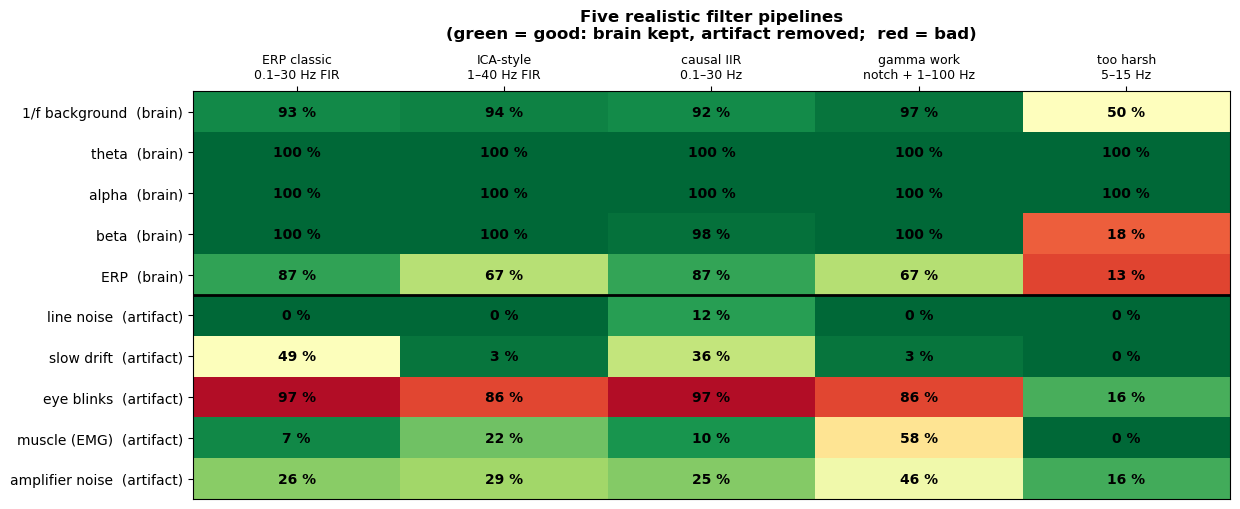

In [40]:
pipelines = {
    "ERP classic\n0.1–30 Hz FIR": lambda r: apply(r, l_freq=0.1, h_freq=30),
    "ICA-style\n1–40 Hz FIR": lambda r: apply(r, l_freq=1, h_freq=40),
    "causal IIR\n0.1–30 Hz": lambda r: apply(r, l_freq=0.1, h_freq=30, method="iir", phase="forward",
                                              iir_params=dict(order=4, ftype="butter")),
    "gamma work\nnotch + 1–100 Hz": lambda r: apply(r.copy().notch_filter(freqs=mains, verbose=False), l_freq=1, h_freq=100),
    "too harsh\n5–15 Hz": lambda r: apply(r, l_freq=5, h_freq=15),
}
_ = plot_scorecard(pipelines, title="Five realistic filter pipelines", trim=20.0)

Notice that **no pipeline is green everywhere**: every pipeline either leaves some artifact behind or removes some brain signal. The best
pipeline depends on the question — which is exactly why it pays to check your own pipeline on simulated data with a known ground truth.

## 9. Interactive filter explorer

Everything above in one place. Pick a channel and a signal type, then play with the filter settings and watch:
* **top left:** a 10 s stretch of the signal before (grey) and after (blue) filtering;
* **top right:** the power spectra before and after;
* **bottom left:** the filter's **magnitude response** (what it does to each frequency), with your cutoffs marked;
* **bottom right:** its **impulse response** (what it does to a single spike). The title reports where the peak lies:
  **0 ms** for zero-phase filters, **> 0 ms** for causal ones (the delay).

Suggestions: (1) *Artifacts only* + Fp1, raise the high-pass from 0 to 1 Hz — watch the drift vanish and the blinks survive.
(2) *Full EEG* + T7, lower the low-pass from 100 to 20 Hz — watch the muscle burst disappear. (3) Tick **causal** and watch the
impulse response move to the right; (4) switch to **IIR** and raise the order; (5) set the **transition bandwidth** to 0.5 Hz
and look at the impulse response again.

Slider notes: **0 switches a filter off**; transition bandwidth 0 = MNE's `'auto'` (FIR only); order is for IIR only.
The sliders update when you release them. (This cell needs a live Jupyter kernel — widgets are not stored in the saved file.)

In [ ]:
EXCERPT = slice(0, int(60 * FS))   # filter the first 60 s of the recording (fast enough for interactive use)
SOURCES = {"Full EEG": "eeg", "Brain only": "brain", "Artifacts only": "artifacts"}


def explore_filter(hp=1.0, lp=40, method="FIR", causal=False, order=4, trans_bw=0.0, channel="Fp1", source="Full EEG"):
    ci = CH_NAMES.index(channel)
    x = sim[SOURCES[source]][ci, EXCERPT]
    l_freq, h_freq = (hp if hp > 0 else None), (lp if lp > 0 else None)
    if l_freq is None and h_freq is None:
        print("Both filters are switched off - move one of the sliders.")
        return
    if l_freq is not None and h_freq is not None and l_freq >= h_freq:
        print("Please set the high-pass cutoff below the low-pass cutoff.")
        return
    kw = dict(l_freq=l_freq, h_freq=h_freq)
    if method == "FIR":
        kw.update(method="fir", phase="minimum" if causal else "zero")
        if trans_bw > 0:
            if l_freq is not None:
                kw["l_trans_bandwidth"] = min(trans_bw, l_freq)
            if h_freq is not None:
                kw["h_trans_bandwidth"] = min(trans_bw, FS / 2 - h_freq)
    else:
        kw.update(method="iir", phase="forward" if causal else "zero", iir_params=dict(order=order, ftype="butter"))
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            y = mne.filter.filter_data(x[None, :], FS, verbose=False, **kw)[0]
            f_r, H, t_ir, imp = measure_filter(**kw)
    except Exception as err:  # e.g. an impossible combination of settings
        print("MNE could not build this filter:", str(err)[:250])
        return

    sl = slice(int(WIN[0] * FS), int(WIN[1] * FS))
    t_all = np.arange(len(x)) / FS
    fig, axes = plt.subplots(2, 2, figsize=(14, 7), gridspec_kw=dict(width_ratios=[1.4, 1]))
    ax = axes[0, 0]
    ax.plot(t_all[sl], x[sl], color="0.65", lw=1, label="before")
    ax.plot(t_all[sl], y[sl], color="tab:blue", lw=1.3, label="after")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude (µV)")
    ax.set_title(f"{channel}, {source}")
    ax.legend(loc="upper right")
    ax = axes[0, 1]
    f, p0 = welch_uV(x, seconds=20)
    _, p1 = welch_uV(y, seconds=20)
    ax.loglog(f[1:], p0[1:], color="0.6", lw=1.5, label="before")
    ax.loglog(f[1:], p1[1:], color="tab:blue", lw=1.5, label="after")
    ax.set_xlim(0.1, 500)
    ax.set_ylim(1e-6, 1e4)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (µV²/Hz)")
    ax.set_title("Power spectrum")
    ax.legend(loc="lower left")
    ax = axes[1, 0]
    ax.semilogx(f_r[1:], 20 * np.log10(np.abs(H[1:]) + 1e-12), color="tab:blue", lw=1.6)
    for c in (l_freq, h_freq):
        if c is not None:
            ax.axvline(c, color="tab:red", ls="--", lw=1.2)
    ax.set_xlim(0.1, 500)
    ax.set_ylim(-100, 5)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Gain (dB)")
    ax.set_title("Filter magnitude response (dashed: your cutoffs)")
    ax = axes[1, 1]
    ax.plot(t_ir, imp, color="tab:blue", lw=1.4)
    delay = 1000 * t_ir[np.argmax(np.abs(imp))]
    ax.set_xlim(-0.5, 0.5)
    ax.set_xlabel("Time (s)")
    ax.set_title(f"Impulse response (largest peak at {delay:+.0f} ms)")
    plt.tight_layout()
    plt.show()


_style = {"description_width": "170px"}
_layout = widgets.Layout(width="520px")
_kw = dict(continuous_update=False, style=_style, layout=_layout)
interact(
    explore_filter,
    hp=widgets.FloatSlider(value=1.0, min=0.0, max=5.0, step=0.1, description="high-pass (Hz, 0 = off)", **_kw),
    lp=widgets.IntSlider(value=40, min=0, max=200, step=1, description="low-pass (Hz, 0 = off)", **_kw),
    method=widgets.ToggleButtons(options=["FIR", "IIR"], description="method", style=_style),
    causal=widgets.Checkbox(value=False, description="causal (no look-ahead, adds delay)", style=_style, layout=_layout),
    order=widgets.IntSlider(value=4, min=1, max=8, step=1, description="IIR order", **_kw),
    trans_bw=widgets.FloatSlider(value=0.0, min=0.0, max=20.0, step=0.5, description="FIR transition bw (Hz, 0 = auto)", **_kw),
    channel=widgets.Dropdown(options=CH_NAMES, value="Fp1", description="channel", style=_style),
    source=widgets.Dropdown(options=list(SOURCES), value="Full EEG", description="signal", style=_style),
);

---
## 10. Take-home messages and further reading

**About EEG waves**
1. EEG is measured in **microvolts**; background EEG is ~10–100 µV and ERPs only a few µV. Always state whether an amplitude is peak,
   peak-to-peak or RMS.
2. The classic bands (delta, theta, alpha, beta, gamma) are not just labels: **slower waves are larger, faster waves smaller**. The
   spectrum falls roughly as **1/f<sup>χ</sup>** (χ ≈ 1–2), with rhythmic peaks such as alpha standing out above it.
3. Rhythms interact: a slow rhythm can modulate the amplitude of a fast one, and an AM signal has energy at the carrier ± the
   modulator frequency — **not at the modulator frequency itself**.
4. Sample fast enough: the sampling rate must exceed **twice** the highest frequency present (Nyquist), otherwise it aliases.

**About filtering with MNE**
5. A filter separates signals **only by frequency**. Where brain activity and artifacts overlap (blinks vs slow waves, gamma vs
   muscle) no filter can separate them perfectly.
6. In MNE, `l_freq`/`h_freq` are **pass-band edges**; the −6 dB point lies half-way through the transition band (and IIR
   "cutoffs" mean −3 dB or −6 dB depending on the phase setting).
7. **High-pass:** removing drift is cheap, but anything above ~0.1–0.5 Hz can start to distort slow ERP components, and zero-phase
   filters leak that distortion to *before* the event.
8. **Low-pass:** sharp ERP features survive a 20–40 Hz low-pass; muscle noise is only removed if you go low enough.
9. **Zero-phase vs causal:** zero-phase = no latency shift but non-causal; causal = no leakage into the past but delays and
   reshapes waves (tens of ms here).
10. **Notch** filters should be narrow; a wide stop-band can erase a signal close to the mains frequency.
11. **Filter continuous data, then epoch**; mind the edges (padding, filter length).
12. **When in doubt, simulate**: check your pipeline on data where you know the answer.

A rough orientation (common *starting points*, not rules — the right values depend on your question):

| Goal | Typical choice | Watch out for |
|---|---|---|
| ERPs / slow components | high-pass ≈ 0.1 Hz (or lower), low-pass ≈ 20–40 Hz, zero-phase FIR | high-pass > ~0.3 Hz distorts slow components |
| ICA decomposition, general clean-up | high-pass ≈ 1 Hz, low-pass ≈ 40–100 Hz | not for ERP amplitudes |
| Oscillations / gamma | higher low-pass, narrow notch, careful artifact handling | muscle and mains overlap with gamma |
| Frequency tagging near the mains frequency | narrow notch or `spectrum_fit`; **never** a wide band-stop | check the spectrum around the notch |
| Real-time / online | causal filter | delay and phase distortion |

**Using your own data.** Replace the simulation by `raw = mne.io.read_raw_*("your_file")`, `raw.load_data()` and apply the same
`raw.copy().filter(...)` calls and plots (`compare_filter`, `measure_filter`, `mne.viz.plot_filter`). The ground-truth scorecards need
simulated data, but the before/after, spectrum and filter-response views work on anything.

**Further reading**
* MNE-Python tutorial *"Background information on filtering"* (mne.tools) — the official, in-depth companion to section 8.
* Widmann, Schröger & Maess (2015), *Digital filter design for electrophysiological data — a practical approach*, J. Neurosci. Methods.
* Tanner, Morgan-Short & Luck (2015), *How inappropriate high-pass filters can produce artifactual effects and incorrect conclusions in
  ERP studies of language and cognition*, Psychophysiology.
* de Cheveigné & Nelken (2019), *Filters: when, why, and how (not) to use them*, Neuron.
* Donoghue et al. (2020), *Parameterizing neural power spectra into periodic and aperiodic components*, Nature Neuroscience (the 1/f
  + peaks view of section 4.3).
* Buzsáki (2006), *Rhythms of the Brain* — a book-length tour of brain oscillations.